<a href="https://colab.research.google.com/github/Migue0110/ACA2_Computaci-n_Nube/blob/main/ACA2_Computacion_en_la_nube_G3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ACA 2 · Computación en la nube
## Ingesta, vectorización y almacenamiento vectorial en clúster cloud para un sistema RAG de permanencia estudiantil y uso de LLM Gemini.

**Especialización en Inteligencia Artificial – CUN** · Docente: Hamilton Rivera Flor
**Pilar sectorial:** Educación · **Dataset base:** UCI Predict Students' Dropout and Academic Success (Martins et al., 2021)
**Stack:** Qdrant Cloud (BD vectorial serverless) + Cohere `embed-multilingual-v3.0` + LangChain Text Splitters + Google Colab

##**Integrantes**

>- Johnny Alirio Blanquicett Cardona.
>- Miguel Orlando Mora Moreno.
>- Ramón Benjamín Buelvas Sierra.
>- Rubby Yesenia Parrado Rodríguez.

 🎥 **Video de sustentación:**

### Objetivo general
Integrar un modelo de lenguaje de gran escala (LLM) —mediante ejecución local con modelos de código abierto como Gemma o Llama, o conectividad cloud vía API con Gemini, Claude o ChatGPT— al sistema de recuperación vectorial implementado en el ACA 1, y desarrollar una interfaz gráfica de usuario interactiva (Streamlit, Gradio o similar) que permita gestionar los documentos base, supervisar el índice vectorial y operar un chatbot conversacional con
capacidades RAG sobre el corpus documental en salud, educación o ventas

### Situación problema
La deserción es un fenómeno multicausal: en el dataset UCI, el **32,1 %** de los estudiantes abandona. Las reglas que orientan la permanencia (becas, periodo de prueba, alertas tempranas, homologación) están dispersas en documentos extensos que estudiantes y tutores no consultan a tiempo. Se necesita una base de conocimiento que permita **recuperar por significado**, en español, tanto la norma aplicable como casos de estudiantes con perfiles similares.

**Pregunta orientadora:** ¿Cómo articular un modelo de lenguaje avanzado (local o cloud) con una base de datos vectorial serverless para construir un chatbot RAG confiable, y desplegar una interfaz gráfica interactiva que facilite la administración documental, la consulta en lenguaje natural y la reducción de alucinaciones con respuestas fundamentadas en evidencia?

### Justificación de las herramientas
| Componente | Elección | Justificación |
|---|---|---|
| BD vectorial | **Qdrant Cloud (Free Tier, 1 GB)** | Serverless, dashboard visual, distancia coseno nativa, **filtrado por payload** (combina búsqueda semántica con condiciones estructuradas del dataset). |
| Embeddings | **Cohere `embed-multilingual-v3.0`** (1024 dim.) | Soporte nativo del español; modos asimétricos `search_document` / `search_query`; API gratuita de desarrollo. |
| Chunking | **`MarkdownHeaderTextSplitter` + `RecursiveCharacterTextSplitter`** | Respeta la jerarquía capítulo → artículo y conserva el encabezado de cada fragmento. |
| Entorno | **Google Colab** | Gratuito y reproducible; credenciales vía Colab Secrets → `.env`. |

> **Nota sobre el Paso 5 de la guía.** La guía sugiere vectorizar la consulta con Gemini Embeddings y la configuración `RETRIEVAL_QUERY`. Como el índice se construyó con Cohere, la consulta **debe** vectorizarse con el mismo modelo: vectores de modelos distintos viven en espacios distintos y no son comparables. El equivalente de Cohere a `RETRIEVAL_QUERY` es `input_type="search_query"`, que es lo que se usa en la Fase 6.

> **Nota sobre el corpus.** Los tres documentos normativos describen una institución **ficticia** (IUAS) y fueron construidos por el equipo para este proyecto. Están alineados con las variables y los códigos del dataset UCI y con normas colombianas reales (Ley 30 de 1992, Ley 1448 de 2011, Ley 1581 de 2012, Ley Estatutaria 1618 de 2013).

## Fase 1. Instalación de dependencias y gestión segura de credenciales (`.env`)

In [ ]:
# Dependencias para el modelo LLM
!pip install -q qdrant-client cohere google-generativeai langchain-text-splitters pandas python-dotenv pyyaml matplotlib

In [ ]:
import os, re, io, time, uuid, zipfile, urllib.request
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cohere

from dotenv import load_dotenv
from qdrant_client import QdrantClient
from qdrant_client.models import (Distance, VectorParams, PointStruct,
                                  Filter, FieldCondition, MatchValue, PayloadSchemaType)
from langchain_text_splitters import MarkdownHeaderTextSplitter, RecursiveCharacterTextSplitter

pd.set_option("display.max_colwidth", 120)

**Gestión segura de credenciales.** Las tres llaves (`COHERE_API_KEY`, `QDRANT_URL`, `QDRANT_API_KEY`) se guardan en **Colab Secrets** (ícono 🔑). La celda siguiente las escribe en un archivo `.env` local del entorno de ejecución, que luego se lee con `python-dotenv`. Ninguna llave queda escrita en el código ni en las salidas. Fuera de Colab, se usa un `.env` creado manualmente. El `.gitignore` evita que el `.env` se suba al repositorio.

In [ ]:
try:
    from google.colab import userdata
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    try:
        claves = {k: userdata.get(k) for k in ("COHERE_API_KEY", "QDRANT_URL", "QDRANT_API_KEY", "GEMINI_API_KEY")}
        with open(".env", "w", encoding="utf-8") as f:
            f.write("\n".join(f"{k}={v}" for k, v in claves.items() if v) + "\n")
        print("✓ Archivo '.env' generado a partir de Colab Secrets.")
    except Exception as e:
        print(f"⚠ No se pudieron leer los secretos: {e}")

load_dotenv(dotenv_path=".env", override=True)
COHERE_API_KEY = os.getenv("COHERE_API_KEY")
QDRANT_URL     = os.getenv("QDRANT_URL")
QDRANT_API_KEY = os.getenv("QDRANT_API_KEY")
GEMINI_API_KEY = os.getenv("GEMINI_API_KEY")

assert all([COHERE_API_KEY, QDRANT_URL, QDRANT_API_KEY, GEMINI_API_KEY]), "❌ Faltan credenciales en el archivo .env"

✓ Archivo '.env' generado a partir de Colab Secrets.


In [ ]:
load_dotenv(dotenv_path=".env", override=True)
COHERE_API_KEY = os.getenv("COHERE_API_KEY")
QDRANT_URL     = os.getenv("QDRANT_URL")
QDRANT_API_KEY = os.getenv("QDRANT_API_KEY")
GEMINI_API_KEY = os.getenv("GEMINI_API_KEY")

assert all([COHERE_API_KEY, QDRANT_URL, QDRANT_API_KEY, GEMINI_API_KEY]), "❌ Faltan credenciales en el archivo .env"
print("✓ Credenciales cargadas con python-dotenv (valores no impresos por seguridad).")

✓ Credenciales cargadas con python-dotenv (valores no impresos por seguridad).


In [ ]:
import google.generativeai as genai
from google.colab import userdata

# Cargar la nueva API Key desde Colab Secrets
GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")
genai.configure(api_key=GEMINI_API_KEY)

# Configurar gemini-3.8-flash
llm_model = genai.GenerativeModel('gemini-3.5-flash-lite')

# Prueba rápida de conexión
respuesta = llm_model.generate_content("Responde solo: Conectado", request_options={"timeout": 15.0})
print(f"✓ Estado Gemini: {respuesta.text.strip()}")

✓ Estado Gemini: Conectado


## Fase 2. Carga de datos, análisis exploratorio y selección de la muestra

El notebook es **autocontenido**: si existen `data.csv` y `docs/*.md` (en Drive o en el directorio local), los usa. Si no existen, descarga el dataset desde el repositorio oficial de UCI y escribe el corpus normativo integrado más abajo. Así se ejecuta de principio a fin en cualquier entorno.

In [ ]:
# Rutas: Drive (opcional) → directorio local
BASE_DIR = "."
if EN_COLAB:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        if os.path.exists("/content/drive/MyDrive/Computación_Nube/ACA1"):
            BASE_DIR = "/content/drive/MyDrive/Computación_Nube/ACA1"
    except Exception as e:
        print(f"ℹ Drive no disponible ({type(e).__name__}); se trabajará en el directorio local.")

DATA_PATH = os.path.join(BASE_DIR, "data.csv")
DOCS_DIR  = os.path.join(BASE_DIR, "docs")

# Descarga del dataset oficial si no existe localmente
UCI_URL = "https://archive.ics.uci.edu/static/public/697/predict+students+dropout+and+academic+success.zip"
if not os.path.exists(DATA_PATH):
    DATA_PATH = "data.csv"
    if not os.path.exists(DATA_PATH):
        print("⇣ Descargando dataset desde UCI Machine Learning Repository...")
        with urllib.request.urlopen(UCI_URL) as r:
            with zipfile.ZipFile(io.BytesIO(r.read())) as z:
                nombre_csv = [n for n in z.namelist() if n.endswith(".csv")][0]
                with open(DATA_PATH, "wb") as f:
                    f.write(z.read(nombre_csv))
print(f"✓ Dataset: {DATA_PATH}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✓ Dataset: /content/drive/MyDrive/Computación_Nube/ACA1/data.csv


### Corpus normativo integrado (respaldo para reproducibilidad)
Si la carpeta `docs/` no existe, esta celda escribe los tres documentos completos en Markdown. Se usa **el mismo corpus** que en la versión de Drive, de modo que los resultados no cambian según el entorno.

In [ ]:
CORPUS_NORMATIVO = {
    "01_reglamento_academico_estudiantil.md": """---
titulo: Reglamento Académico Estudiantil
institucion: Institución Universitaria Andina del Saber (IUAS) — institución ficticia elaborada con fines académicos
tipo_documento: reglamento_academico
pilar: educacion
version: "1.0"
fecha: 2026-10
idioma: es
dataset_base: UCI Predict Students Dropout and Academic Success (Martins et al., 2021)
variables_dataset_relacionadas:
  - Application mode
  - Application order
  - Course
  - Daytime/evening attendance
  - Previous qualification (grade)
  - Admission grade
  - Age at enrollment
  - Tuition fees up to date
  - Debtor
  - Scholarship holder
  - Curricular units 1st/2nd sem (enrolled, evaluations, approved, grade, without evaluations)
  - Target (Dropout, Enrolled, Graduate)
---

# REGLAMENTO ACADÉMICO ESTUDIANTIL

**Institución Universitaria Andina del Saber (IUAS)**
*Documento elaborado como corpus de referencia para un sistema de consulta académica basado en recuperación aumentada (RAG). La institución es ficticia.*

---

## CAPÍTULO I. DISPOSICIONES GENERALES

### Artículo 1. Objeto
El presente reglamento establece las normas que rigen la vida académica de los estudiantes de pregrado de la IUAS, desde la admisión hasta la obtención del título, incluyendo matrícula, evaluación, rendimiento académico, permanencia, retiro, reintegro y grado.

### Artículo 2. Ámbito de aplicación
Este reglamento aplica a todos los estudiantes matriculados en los programas de pregrado de la IUAS, en jornada diurna o nocturna, en modalidad presencial.

### Artículo 3. Principios
La vida académica de la IUAS se orienta por los principios de calidad, equidad, inclusión, transparencia, debido proceso, corresponsabilidad y permanencia con éxito. La institución reconoce que el abandono de los estudios es un fenómeno multicausal y se compromete a prevenirlo mediante acciones académicas, psicopedagógicas, socioeconómicas e institucionales.

### Artículo 4. Definiciones
Para efectos de este reglamento se adoptan las siguientes definiciones:

- **Estudiante:** persona que tiene matrícula académica y financiera vigente en un programa de la IUAS.
- **Unidad curricular:** asignatura, curso o módulo que forma parte del plan de estudios y tiene un número de créditos asignado.
- **Crédito académico:** unidad que mide el trabajo académico del estudiante; un crédito equivale a 48 horas de trabajo entre acompañamiento docente y trabajo independiente.
- **Período académico o semestre:** lapso de dieciséis (16) semanas de actividades académicas más el periodo de evaluaciones finales.
- **Unidad curricular inscrita:** unidad en la que el estudiante se matriculó en un semestre.
- **Unidad curricular aprobada:** unidad en la que el estudiante obtuvo una calificación final igual o superior a la nota mínima aprobatoria.
- **Unidad curricular sin evaluación:** unidad inscrita en la que el estudiante no presentó ninguna de las evaluaciones previstas.
- **Unidad curricular acreditada (reconocida):** unidad aprobada en otro programa o institución y reconocida por la IUAS mediante homologación, conforme a la Guía de Homologación institucional.
- **Tasa de aprobación semestral:** cociente entre unidades curriculares aprobadas y unidades curriculares inscritas en el semestre.
- **Deserción o abandono:** situación del estudiante que, sin haber obtenido el título, no renueva su matrícula durante dos (2) semestres consecutivos sin haber solicitado aplazamiento.
- **Permanencia:** continuidad del estudiante en el programa hasta su graduación.
- **Graduado:** estudiante que cumplió todos los requisitos y recibió el título.

---

## CAPÍTULO II. ADMISIÓN E INGRESO

### Artículo 5. Modalidades de ingreso
La IUAS admite estudiantes a través de las siguientes modalidades:

1. **Régimen general — primera fase** (código de referencia en el dataset: 1): aspirantes que culminaron la educación media y presentan la prueba de Estado.
2. **Régimen general — segunda y tercera fase** (códigos 17 y 18): convocatorias complementarias para cupos no ocupados en la primera fase.
3. **Mayores de 23 años** (código 39): aspirantes que no cumplen los requisitos ordinarios pero superan una prueba especial de aptitud y presentan su trayectoria laboral.
4. **Titulados de otro programa de educación superior** (código 7): profesionales que desean cursar un segundo programa.
5. **Titulados de programas técnicos o tecnológicos** (códigos 44 y 53): aspirantes con diplomas de especialización tecnológica o de ciclo corto.
6. **Transferencia externa** (código 42): estudiantes provenientes de otra institución de educación superior.
7. **Cambio de programa o transferencia interna** (código 43): estudiantes de la IUAS que solicitan trasladarse a otro programa.
8. **Estudiantes internacionales** (código 15): aspirantes con estudios secundarios realizados en el exterior.
9. **Regímenes especiales:** víctimas del conflicto armado y población desplazada, comunidades étnicas, personas con discapacidad y deportistas de alto rendimiento, con cupos reservados según la política de inclusión.

### Artículo 6. Orden de preferencia
En el formulario de inscripción el aspirante puede señalar hasta nueve (9) programas en orden de preferencia, de 0 (primera opción) a 9 (última opción). La institución registra este orden porque los estudiantes admitidos en una opción distinta a la primera pueden requerir orientación vocacional temprana.

### Artículo 7. Puntaje de admisión
El puntaje de admisión se expresa en una escala de 0 a 200 puntos y se compone de:

- 50 % calificación de los estudios previos (escala 0–200);
- 50 % resultado de la prueba de ingreso o de la prueba de Estado normalizada.

El puntaje mínimo para ser admitido es de **95 puntos**. Los admitidos con puntaje inferior a **120 puntos** serán remitidos automáticamente al programa de nivelación y al Sistema de Alertas Tempranas descrito en el Protocolo de Acompañamiento Psicopedagógico.

### Artículo 8. Requisitos de inscripción
- Documento de identidad.
- Diploma y acta de grado de educación media, o su equivalente convalidado.
- Resultado de la prueba de Estado o de la prueba de ingreso.
- Para transferencias y titulados: certificado de calificaciones y contenidos programáticos.
- Para regímenes especiales: certificación de la condición (por ejemplo, inscripción en el Registro Único de Víctimas o certificado de discapacidad).

### Artículo 9. Edad de ingreso
No existe límite de edad para ingresar. La institución registra la edad al momento de la matrícula con el fin de ofrecer acompañamiento diferenciado a estudiantes que combinan estudio, trabajo y responsabilidades familiares.

---

## CAPÍTULO III. MATRÍCULA

### Artículo 10. Matrícula académica y financiera
La calidad de estudiante se adquiere con la matrícula, que tiene dos componentes:

- **Matrícula financiera:** pago de los derechos de matrícula o formalización de un acuerdo de pago, beca o crédito.
- **Matrícula académica:** inscripción de las unidades curriculares del semestre en el sistema de información académica.

### Artículo 11. Jornadas
Los programas se ofrecen en jornada **diurna** (lunes a viernes, 7:00 a. m. a 6:00 p. m.) o **nocturna** (lunes a viernes, 6:00 p. m. a 10:00 p. m., y sábados). El estudiante puede solicitar cambio de jornada una vez por semestre, sujeto a disponibilidad de cupos.

### Artículo 12. Carga académica
- **Carga mínima:** 12 créditos por semestre para la jornada diurna y 8 créditos para la jornada nocturna.
- **Carga máxima:** 21 créditos por semestre.
- Los estudiantes en periodo de prueba académica solo podrán inscribir hasta 14 créditos.
- Los estudiantes con unidades acreditadas por homologación ajustarán su carga según el plan de transición que defina el comité de programa.

### Artículo 13. Matrícula extemporánea
Se podrá realizar matrícula extemporánea durante las dos primeras semanas del semestre, con un recargo del 10 % sobre el valor de la matrícula.

### Artículo 14. Cancelación de unidades curriculares
El estudiante puede cancelar unidades curriculares hasta la semana ocho (8) del semestre sin efecto en su promedio. La cancelación no exime del pago y la unidad no se registra como reprobada ni como "sin evaluación".

### Artículo 15. Aplazamiento del semestre
El estudiante puede aplazar el semestre por motivos de salud, trabajo, situación económica, calamidad familiar u otra causa justificada, hasta por dos (2) semestres consecutivos. El aplazamiento debe solicitarse antes de la semana diez (10). Antes de aprobarlo, la Coordinación de Permanencia realizará una entrevista para identificar alternativas que permitan continuar los estudios.

---

## CAPÍTULO IV. OBLIGACIONES FINANCIERAS, BECAS Y ESTÍMULOS

### Artículo 16. Pago de matrícula
Los derechos de matrícula se pagan antes del inicio del semestre. El estudiante puede optar por pago único, pago en cuotas (hasta cuatro cuotas mensuales) o financiación mediante crédito educativo.

### Artículo 17. Estudiante con obligaciones pendientes (deudor)
Se considera **estudiante deudor** a quien tiene obligaciones económicas vencidas con la institución. Se considera que el estudiante **no está al día con la matrícula** cuando, al cierre de la semana seis (6), no ha pagado la cuota correspondiente.

La condición de deudor:
- **No impide** asistir a clases ni presentar evaluaciones durante el semestre en curso.
- Impide la expedición de certificados y la renovación de matrícula para el semestre siguiente hasta que se firme un acuerdo de pago.
- Genera de forma automática una **alerta socioeconómica** en el Sistema de Alertas Tempranas y la remisión a la Oficina de Apoyo Financiero.

### Artículo 18. Acuerdos de pago
El estudiante deudor puede suscribir un acuerdo de pago de hasta seis (6) cuotas sin intereses. La institución no condicionará la firma del acuerdo al pago de un abono inicial cuando el estudiante acredite dificultad económica sobreviniente.

### Artículo 19. Becas
La IUAS otorga las siguientes becas:

| Tipo de beca | Cobertura | Requisito de mantenimiento |
|---|---|---|
| Beca de excelencia académica | 50 % a 100 % de la matrícula | Promedio semestral ≥ 15/20 y aprobación del 100 % de las unidades inscritas |
| Beca socioeconómica | 30 % a 70 % | Promedio ≥ 11/20 y aprobación ≥ 75 % de unidades inscritas |
| Beca de inclusión (víctimas, desplazados, étnicos, discapacidad) | 50 % a 100 % | Aprobación ≥ 60 % de unidades inscritas y participación en el plan de acompañamiento |
| Beca deportiva y cultural | 25 % a 50 % | Promedio ≥ 12/20 y participación en los grupos representativos |

### Artículo 20. Pérdida y recuperación de la beca
La beca se suspende cuando el estudiante no cumple el requisito de mantenimiento. Antes de suspenderla, el estudiante será citado por la Coordinación de Permanencia y tendrá un semestre de gracia si se compromete con un plan de acompañamiento. La beca podrá recuperarse en el semestre siguiente al cumplir nuevamente los requisitos.

---

## CAPÍTULO V. EVALUACIÓN ACADÉMICA

### Artículo 21. Escala de calificaciones
Las calificaciones se expresan en una escala de **0 a 20**, con una cifra decimal. La **nota mínima aprobatoria es 10,0**. Para fines de certificación nacional se aplica la siguiente equivalencia:

| Escala IUAS (0–20) | Escala 0,0–5,0 | Desempeño |
|---|---|---|
| 18,0 – 20,0 | 4,6 – 5,0 | Excelente |
| 15,0 – 17,9 | 4,0 – 4,5 | Sobresaliente |
| 12,0 – 14,9 | 3,4 – 3,9 | Bueno |
| 10,0 – 11,9 | 3,0 – 3,3 | Aceptable (aprobado) |
| 0,0 – 9,9 | 0,0 – 2,9 | Insuficiente (reprobado) |

### Artículo 22. Componentes de la evaluación
Cada unidad curricular tendrá como mínimo tres (3) evaluaciones por semestre, ninguna con peso superior al 40 %. El docente debe dar a conocer el plan de evaluación en la primera semana de clases y registrar las calificaciones parciales en el sistema dentro de los ocho (8) días hábiles siguientes a cada evaluación.

### Artículo 23. Unidad curricular sin evaluación
Cuando el estudiante no presenta ninguna evaluación de una unidad inscrita y no la canceló oportunamente, la unidad se registra como **"sin evaluación"** con calificación 0,0. Dos o más unidades sin evaluación en un mismo semestre generan una **alerta de abandono temprano**, porque suelen indicar que el estudiante dejó de asistir.

### Artículo 24. Evaluaciones supletorias
El estudiante que no presente una evaluación por causa justificada (enfermedad, calamidad, obligación laboral sobreviniente o representación institucional) podrá solicitar una evaluación supletoria dentro de los cinco (5) días hábiles siguientes, aportando el soporte correspondiente.

### Artículo 25. Evaluación de recuperación
El estudiante que obtenga una calificación final entre 7,0 y 9,9 podrá presentar una evaluación de recuperación por unidad curricular. La nota máxima que se registra tras la recuperación es 10,0.

### Artículo 26. Revisión de calificaciones
El estudiante puede solicitar por escrito la revisión de una calificación ante el docente dentro de los tres (3) días hábiles siguientes a su publicación. Si persiste el desacuerdo, puede solicitar un segundo calificador ante la dirección del programa.

### Artículo 27. Promedio semestral
El promedio semestral es el promedio ponderado por créditos de las calificaciones finales de las unidades aprobadas en el semestre. Para efectos de seguimiento de la permanencia, la institución calcula además:

- El **número de unidades inscritas, evaluadas, aprobadas y sin evaluación** en el primer y segundo semestre.
- La **tasa de aprobación semestral** (aprobadas / inscritas).

---

## CAPÍTULO VI. RENDIMIENTO ACADÉMICO Y PERMANENCIA

### Artículo 28. Situaciones académicas
Al finalizar cada semestre, el estudiante se encontrará en una de las siguientes situaciones:

| Situación | Criterio | Consecuencia |
|---|---|---|
| Normal | Tasa de aprobación ≥ 60 % y promedio ≥ 10,0 | Continúa sin restricciones |
| Alerta académica | Tasa de aprobación entre 50 % y 59 %, o promedio entre 10,0 y 10,9 | Tutoría obligatoria en el semestre siguiente |
| Periodo de prueba | Tasa de aprobación < 50 %, o promedio < 10,0 | Carga máxima de 14 créditos y plan de acompañamiento obligatorio |
| Bajo rendimiento reiterado | Dos periodos de prueba consecutivos | Estudio del caso por el Comité de Permanencia |

### Artículo 29. Primer año como periodo crítico
La IUAS reconoce que el primer año, y en particular el **resultado del primer semestre**, es el momento de mayor riesgo de abandono. Por ello, todo estudiante de primer semestre que al cierre de la semana ocho (8) tenga calificaciones parciales inferiores a 10,0 en la mitad o más de sus unidades inscritas será contactado por un tutor dentro de los cinco (5) días hábiles siguientes.

### Artículo 30. Plan de acompañamiento obligatorio
El estudiante en periodo de prueba firmará un plan de acompañamiento con la Coordinación de Permanencia, que puede incluir tutorías, monitorías, talleres de hábitos de estudio, asesoría psicológica, apoyo financiero o reorientación vocacional, según lo establecido en el Protocolo de Acompañamiento Psicopedagógico.

### Artículo 31. Comité de Permanencia
El Comité de Permanencia está integrado por la Vicerrectoría Académica, la Dirección de Bienestar, la Coordinación de Permanencia, la dirección del programa y un representante estudiantil. Analiza los casos de bajo rendimiento reiterado y decide, entre otras opciones: prorrogar el periodo de prueba, recomendar un cambio de programa o jornada, o autorizar un aplazamiento con plan de retorno. **La pérdida de la calidad de estudiante por rendimiento solo procede cuando se han agotado las rutas de acompañamiento y se ha garantizado el derecho de defensa.**

---

## CAPÍTULO VII. RETIRO, DESERCIÓN Y REINTEGRO

### Artículo 32. Retiro voluntario
El estudiante puede retirarse voluntariamente en cualquier momento mediante solicitud escrita. Antes de formalizar el retiro, se realizará una **entrevista de salida** en la que se registrarán los motivos (académicos, económicos, laborales, familiares, de salud, vocacionales o institucionales) y se presentarán alternativas como el aplazamiento, el cambio de jornada o la reducción de carga.

### Artículo 33. Deserción
Se considera que un estudiante **abandonó sus estudios** cuando no renueva matrícula durante dos (2) semestres consecutivos sin haber solicitado aplazamiento. La institución registra la deserción por cohorte y por semestre para el Sistema de Alertas Tempranas y para el reporte al sistema nacional de seguimiento de la deserción.

### Artículo 34. Reintegro
El estudiante que se retiró o abandonó puede solicitar reintegro dentro de los cinco (5) años siguientes a su último semestre cursado. El reintegro está sujeto a:
- disponibilidad de cupo;
- paz y salvo financiero o acuerdo de pago;
- estudio del plan de estudios vigente y, si es necesario, homologación de las unidades cursadas.

El estudiante reintegrado será incluido automáticamente en el plan de acompañamiento durante su primer semestre de retorno.

---

## CAPÍTULO VIII. GRADO

### Artículo 35. Requisitos de grado
Para obtener el título se requiere:
1. Aprobar la totalidad de los créditos del plan de estudios, incluidos los acreditados por homologación.
2. Cumplir el requisito de segunda lengua.
3. Aprobar la opción de grado (trabajo de grado, práctica profesional, seminario de profundización o examen de grado).
4. Estar a paz y salvo con la institución.

### Artículo 36. Tiempo máximo de permanencia
El tiempo máximo para culminar el programa es el doble de la duración nominal del plan de estudios, sin contar los semestres aplazados oficialmente.

### Artículo 37. Distinciones
Se otorga grado con mención honorífica al estudiante con promedio acumulado igual o superior a 17,0 que no haya reprobado ninguna unidad curricular.

---

## CAPÍTULO IX. DERECHOS Y DEBERES ACADÉMICOS

### Artículo 38. Derechos
Son derechos del estudiante, entre otros: conocer oportunamente el plan de evaluación; recibir retroalimentación de sus evaluaciones; solicitar revisión de calificaciones; acceder a tutorías, monitorías y servicios de bienestar; recibir ajustes razonables cuando tenga necesidades educativas especiales; y conocer el uso que la institución da a sus datos personales.

### Artículo 39. Deberes
Son deberes del estudiante: asistir a sus actividades académicas; presentar sus evaluaciones; informar oportunamente situaciones que afecten su continuidad; cumplir los compromisos del plan de acompañamiento cuando aplique; y mantener actualizados sus datos de contacto.

---

## CAPÍTULO X. DISPOSICIONES FINALES

### Artículo 40. Interpretación
Los vacíos de este reglamento serán resueltos por el Consejo Académico, aplicando el principio de favorabilidad para el estudiante.

### Artículo 41. Vigencia
El presente reglamento rige a partir de su publicación y deroga las disposiciones que le sean contrarias.

---

## ANEXO 1. Programas académicos de pregrado

| Código de referencia (dataset) | Programa | Jornada |
|---|---|---|
| 33 | Tecnología en Producción de Biocombustibles | Diurna |
| 171 | Diseño de Animación y Multimedia | Diurna |
| 8014 | Trabajo Social | Nocturna |
| 9003 | Agronomía | Diurna |
| 9070 | Diseño de Comunicación | Diurna |
| 9085 | Enfermería Veterinaria | Diurna |
| 9119 | Ingeniería Informática | Diurna |
| 9130 | Equinocultura | Diurna |
| 9147 | Administración | Diurna |
| 9238 | Trabajo Social | Diurna |
| 9254 | Turismo | Diurna |
| 9500 | Enfermería | Diurna |
| 9556 | Higiene Oral | Diurna |
| 9670 | Gestión de Publicidad y Mercadeo | Diurna |
| 9773 | Periodismo y Comunicación | Diurna |
| 9853 | Educación Básica | Diurna |
| 9991 | Administración | Nocturna |
""",
    "02_protocolo_acompanamiento_psicopedagogico.md": """---
titulo: Protocolo de Acompañamiento Psicopedagógico y Sistema de Alertas Tempranas para la Permanencia Estudiantil
institucion: Institución Universitaria Andina del Saber (IUAS) — institución ficticia elaborada con fines académicos
tipo_documento: protocolo_psicopedagogico
pilar: educacion
version: "1.0"
fecha: 2026-10
idioma: es
dataset_base: UCI Predict Students Dropout and Academic Success (Martins et al., 2021)
variables_dataset_relacionadas:
  - Curricular units 1st/2nd sem (enrolled, evaluations, approved, grade, without evaluations)
  - Tuition fees up to date
  - Debtor
  - Scholarship holder
  - Age at enrollment
  - Daytime/evening attendance
  - Displaced
  - Educational special needs
  - Marital status
  - Mother's qualification / Father's qualification
  - Admission grade
  - Application order
  - Unemployment rate / Inflation rate / GDP
  - Target (Dropout, Enrolled, Graduate)
documentos_relacionados:
  - 01_reglamento_academico_estudiantil
  - 03_guia_homologacion_reconocimiento_creditos
---

# PROTOCOLO DE ACOMPAÑAMIENTO PSICOPEDAGÓGICO Y SISTEMA DE ALERTAS TEMPRANAS PARA LA PERMANENCIA ESTUDIANTIL

**Institución Universitaria Andina del Saber (IUAS)**
*Dirección de Bienestar Universitario — Coordinación de Permanencia Estudiantil*
*Documento elaborado como corpus de referencia para un sistema de consulta académica basado en recuperación aumentada (RAG). La institución es ficticia.*

---

## 1. PRESENTACIÓN

La deserción estudiantil es uno de los principales desafíos de la educación superior. Sus causas no son únicamente académicas: intervienen factores individuales, familiares, económicos, vocacionales e institucionales que se combinan de forma distinta en cada estudiante. Este protocolo establece cómo la IUAS detecta oportunamente a los estudiantes en riesgo de abandonar sus estudios y cómo los acompaña para que permanezcan y se gradúen.

El protocolo integra dos componentes:

1. **El Sistema de Alertas Tempranas (SAT):** conjunto de indicadores y umbrales que permiten identificar el riesgo de abandono a partir de la información académica, socioeconómica y demográfica del estudiante.
2. **Las Rutas de Acompañamiento:** procedimientos de atención académica, psicológica, socioeconómica, de inclusión y vocacional que se activan según el tipo y el nivel del riesgo.

## 2. OBJETIVOS

### 2.1 Objetivo general
Prevenir la deserción y favorecer la permanencia con éxito de los estudiantes de la IUAS mediante la detección temprana del riesgo y la atención oportuna, integral y diferenciada.

### 2.2 Objetivos específicos
- Identificar, desde la admisión, a los estudiantes con factores de riesgo de abandono.
- Monitorear el desempeño académico del primer y segundo semestre, que son los periodos de mayor riesgo.
- Activar rutas de atención en tiempos definidos según el nivel de alerta.
- Articular las dependencias académicas, de bienestar y financieras alrededor de cada caso.
- Medir la efectividad de las acciones mediante indicadores de retención y graduación.

## 3. ALCANCE

Aplica a todos los estudiantes de pregrado, con énfasis en los estudiantes de primer año, los estudiantes en periodo de prueba académica, los estudiantes reintegrados y los estudiantes que ingresaron por transferencia o cambio de programa.

## 4. MARCO DE REFERENCIA

El protocolo se fundamenta en:

- **Ley 30 de 1992**, que organiza el servicio público de la educación superior y ordena a las instituciones adelantar programas de bienestar.
- **Acuerdo 03 de 1995 del Consejo Nacional de Educación Superior (CESU)**, que establece las políticas de bienestar universitario.
- **Ley 1448 de 2011**, sobre atención y reparación a las víctimas del conflicto armado, que incluye medidas de acceso y permanencia en la educación superior.
- **Ley 1581 de 2012**, sobre protección de datos personales.
- **Ley Estatutaria 1618 de 2013**, que garantiza los derechos de las personas con discapacidad, incluidos los ajustes razonables en la educación.
- **Ley 1616 de 2013**, de salud mental.
- Los lineamientos del Ministerio de Educación Nacional sobre permanencia y graduación estudiantil, y el Sistema para la Prevención de la Deserción en la Educación Superior (SPADIES).
- El modelo de integración académica y social de Tinto, según el cual la permanencia depende del grado en que el estudiante se integra a la vida académica y social de la institución.

## 5. ENFOQUE DEL ACOMPAÑAMIENTO

- **Multicausal:** ningún factor explica por sí solo la deserción; el riesgo se evalúa combinando variables.
- **Preventivo:** se actúa antes de que el estudiante abandone, no después.
- **Diferencial:** se reconocen las condiciones particulares de estudiantes víctimas, desplazados, con discapacidad, de comunidades étnicas, trabajadores, padres o madres de familia y estudiantes de primera generación.
- **Corresponsable:** la permanencia es responsabilidad compartida entre el estudiante, los docentes, las familias y la institución.
- **No sancionatorio:** una alerta nunca es una sanción ni se registra en la hoja de vida académica.

## 6. SISTEMA DE ALERTAS TEMPRANAS (SAT)

### 6.1 Fuentes de información
El SAT se alimenta de:
- el formulario de inscripción y la caracterización socioeconómica al ingreso;
- el sistema de información académica (unidades inscritas, evaluadas, aprobadas, sin evaluación y calificaciones);
- el sistema financiero (estado de pago de la matrícula, condición de deudor, becas);
- los reportes de docentes y tutores;
- los indicadores económicos del contexto (tasa de desempleo, inflación y crecimiento del PIB), que se usan para análisis institucional y no para evaluar a estudiantes individuales.

### 6.2 Factores de riesgo e indicadores

| Dimensión | Factor de riesgo | Variable del dataset | Indicador / umbral | Puntos |
|---|---|---|---|---|
| Académica | Baja aprobación en primer semestre | Curricular units 1st sem (approved) / (enrolled) | Tasa de aprobación < 50 % | 3 |
| Académica | Baja aprobación en segundo semestre | Curricular units 2nd sem (approved) / (enrolled) | Tasa de aprobación < 50 % | 3 |
| Académica | Promedio insuficiente | Curricular units 1st/2nd sem (grade) | Promedio < 10,0 | 2 |
| Académica | Ausencia en evaluaciones | Curricular units 1st/2nd sem (without evaluations) | 2 o más unidades sin evaluación | 2 |
| Académica | Puntaje de admisión bajo | Admission grade | < 120 puntos (escala 0–200) | 1 |
| Vocacional | Programa no fue primera opción | Application order | Orden de preferencia ≥ 3 | 1 |
| Socioeconómica | Matrícula no al día | Tuition fees up to date | = 0 (no al día) | 3 |
| Socioeconómica | Obligaciones vencidas | Debtor | = 1 (deudor) | 2 |
| Socioeconómica | Sin apoyo económico | Scholarship holder | = 0 y además deudor | 1 |
| Individual | Ingreso en edad adulta | Age at enrollment | > 25 años | 1 |
| Individual | Responsabilidades familiares | Marital status | Casado(a), unión de hecho, divorciado(a) o viudo(a) | 1 |
| Individual | Jornada nocturna (estudiante trabajador) | Daytime/evening attendance | = 0 (nocturna) | 1 |
| Familiar | Primera generación universitaria | Mother's / Father's qualification | Ningún progenitor con educación superior | 1 |
| Diferencial | Condición de desplazamiento | Displaced | = 1 | Ruta diferencial obligatoria |
| Diferencial | Necesidades educativas especiales | Educational special needs | = 1 | Ruta de inclusión obligatoria |

**Justificación de los factores con mayor puntaje.** En el análisis histórico de las cohortes, los factores que mejor anticipan el abandono son el **rendimiento del primer y segundo semestre** (unidades aprobadas y calificación) y la **situación de pago de la matrícula**. Por eso reciben el mayor puntaje. Los factores individuales y familiares tienen menor peso por sí solos, pero aumentan el riesgo cuando se combinan con dificultades académicas o económicas.

### 6.3 Niveles de alerta (semáforo)

| Nivel | Puntaje total | Significado | Tiempo máximo de contacto |
|---|---|---|---|
| 🟢 Verde | 0 – 2 | Riesgo bajo | Seguimiento general en las actividades de bienestar |
| 🟡 Amarillo | 3 – 5 | Riesgo moderado | 10 días hábiles |
| 🔴 Rojo | 6 o más | Riesgo alto de abandono | 3 días hábiles |

Independientemente del puntaje, se activa **alerta roja** cuando:
- el estudiante tiene tres (3) o más unidades sin evaluación en un semestre;
- el estudiante no está al día con la matrícula **y** su tasa de aprobación es inferior al 50 %;
- un docente, compañero o familiar reporta una situación de crisis emocional o riesgo para la vida del estudiante (en este caso se activa además la Ruta de Atención en Crisis).

### 6.4 Momentos críticos de medición
El SAT se actualiza en cinco momentos del año académico:

1. **Admisión e inducción:** factores de ingreso (puntaje de admisión, orden de preferencia, edad, jornada, condición diferencial, nivel educativo de los padres).
2. **Semana 6:** estado de pago de la matrícula y asistencia reportada por docentes.
3. **Semana 8 (primeros parciales):** calificaciones parciales y evaluaciones no presentadas.
4. **Cierre del primer semestre:** unidades aprobadas, promedio y unidades sin evaluación del primer semestre. **Este es el momento más importante para prevenir el abandono.**
5. **Cierre del segundo semestre y renovación de matrícula:** resultados del segundo semestre y estudiantes que no renovaron matrícula.

### 6.5 Uso ético de los modelos predictivos
La IUAS puede apoyarse en modelos estadísticos o de aprendizaje automático para estimar la probabilidad de abandono. Su uso se rige por estas reglas:
- El resultado del modelo es **una alerta para orientar el acompañamiento**, nunca una decisión automatizada sobre admisión, becas, sanciones o permanencia.
- Toda alerta generada por un modelo debe ser revisada por un profesional antes de contactar al estudiante.
- Se revisará periódicamente que el modelo no discrimine por sexo, edad, nacionalidad, estado civil, condición de desplazamiento o discapacidad.
- Las variables sensibles se usan para ofrecer más apoyo, no para excluir.

## 7. ROLES Y RESPONSABILIDADES

| Rol | Responsabilidades |
|---|---|
| **Docente** | Registrar calificaciones a tiempo; reportar inasistencias reiteradas (más de dos semanas) y señales de dificultad académica o emocional. |
| **Tutor académico** | Acompañar a los estudiantes en alerta amarilla o roja; diseñar con ellos el plan de estudio; hacer seguimiento quincenal. |
| **Monitor (estudiante par)** | Apoyar en asignaturas de alta reprobación; facilitar la integración social de estudiantes de primer semestre. |
| **Psicopedagogo(a)** | Valorar dificultades de aprendizaje, hábitos de estudio y orientación vocacional; diseñar ajustes razonables. |
| **Psicólogo(a)** | Brindar primeros auxilios psicológicos, consejería y remisión a la red de salud mental. |
| **Oficina de Apoyo Financiero** | Gestionar acuerdos de pago, becas, auxilios y crédito educativo. |
| **Coordinación de Permanencia** | Administrar el SAT, asignar casos, convocar el Comité de Permanencia y reportar indicadores. |
| **Dirección de programa** | Analizar las unidades curriculares con alta reprobación y proponer mejoras pedagógicas. |

## 8. RUTAS DE ACOMPAÑAMIENTO

### 8.1 Ruta 1 — Académica
**Se activa cuando:** tasa de aprobación < 60 %, promedio < 11,0, unidades sin evaluación, o puntaje de admisión < 120.

**Acciones:**
1. Entrevista inicial con el tutor académico.
2. Diagnóstico de las causas: vacíos de formación previa, carga excesiva, métodos de estudio, cruce con jornada laboral.
3. Plan de estudio personalizado: tutorías semanales, monitorías en las unidades de mayor dificultad, talleres de técnicas de estudio y gestión del tiempo.
4. Ajuste de la carga académica para el semestre siguiente cuando sea necesario.
5. Seguimiento en las semanas 4, 8 y 12.

### 8.2 Ruta 2 — Psicológica y socioemocional
**Se activa cuando:** el estudiante o un tercero reporta estrés, ansiedad, desmotivación, duelo, conflictos familiares o de pareja, consumo problemático de sustancias o cualquier situación emocional que afecte sus estudios.

**Acciones:**
1. Primera escucha y valoración por psicología en máximo 3 días hábiles.
2. Consejería individual (hasta 6 sesiones por semestre) o talleres grupales.
3. Remisión a la entidad de salud del estudiante cuando se requiera atención clínica.
4. Coordinación con el tutor académico, con autorización del estudiante, para flexibilizar plazos.

**Ruta de Atención en Crisis:** cuando exista riesgo para la vida o la integridad del estudiante, cualquier miembro de la comunidad debe comunicarse de inmediato con Bienestar Universitario; la institución activará la atención de urgencias y las líneas de salud mental del territorio y acompañará al estudiante hasta que esté en manos de la red de salud.

### 8.3 Ruta 3 — Socioeconómica
**Se activa cuando:** el estudiante no está al día con la matrícula, figura como deudor, pierde una beca o reporta una dificultad económica sobreviniente (pérdida de empleo propio o de un familiar, por ejemplo).

**Acciones:**
1. Contacto de la Oficina de Apoyo Financiero en máximo 5 días hábiles.
2. Estudio socioeconómico y propuesta de acuerdo de pago, beca socioeconómica, auxilio de transporte o alimentación, o crédito educativo.
3. Información sobre convocatorias externas de financiación.
4. Verificación de que la situación financiera no esté afectando el rendimiento académico; si es así, remisión simultánea a la Ruta 1.

**Nota:** en periodos de aumento del desempleo o de la inflación, la Coordinación de Permanencia ampliará la convocatoria de apoyos, porque estas condiciones del contexto suelen incrementar el número de estudiantes con dificultades de pago.

### 8.4 Ruta 4 — Inclusión y ajustes razonables
**Se activa cuando:** el estudiante reporta necesidades educativas especiales o discapacidad.

**Acciones:**
1. Valoración psicopedagógica de las barreras para el aprendizaje y la participación.
2. Elaboración de un **Plan Individual de Ajustes Razonables (PIAR-ES)**, que puede incluir: tiempo adicional en evaluaciones, formatos accesibles, intérprete de lengua de señas, tecnologías de apoyo o adecuaciones de espacio.
3. Comunicación del plan a los docentes, con autorización del estudiante.
4. Revisión del plan al inicio de cada semestre.

### 8.5 Ruta 5 — Diferencial para víctimas, población desplazada y comunidades étnicas
**Se activa cuando:** el estudiante se encuentra en condición de desplazamiento, es víctima del conflicto armado o pertenece a una comunidad étnica.

**Acciones:**
1. Bienvenida y caracterización con enfoque diferencial y de no revictimización.
2. Priorización en becas de inclusión, auxilios y alojamiento cuando esté disponible.
3. Acompañamiento psicosocial con profesionales formados en enfoque diferencial.
4. Articulación con las entidades del sistema de atención a víctimas.
5. Tutoría académica preventiva durante el primer año, aunque no exista alerta académica.

### 8.6 Ruta 6 — Orientación vocacional y reorientación
**Se activa cuando:** el estudiante fue admitido en un programa que no era su primera opción, manifiesta dudas sobre su elección o presenta bajo rendimiento concentrado en las unidades propias de la disciplina.

**Acciones:**
1. Entrevista vocacional y aplicación de pruebas de intereses y aptitudes.
2. Información sobre los planes de estudio y el perfil profesional de otros programas.
3. Cuando sea pertinente, acompañamiento para el **cambio de programa o de jornada**, con estudio de homologación según la Guía de Homologación y Reconocimiento de Créditos. El cambio de programa se considera una estrategia de permanencia, no un fracaso.

### 8.7 Ruta 7 — Estudiante trabajador, adulto y con responsabilidades familiares
**Se activa cuando:** el estudiante ingresó con más de 25 años, estudia en jornada nocturna, trabaja o tiene personas a su cargo.

**Acciones:**
1. Orientación para planear una carga académica compatible con su jornada laboral.
2. Acceso preferente a tutorías en horario nocturno o virtual.
3. Flexibilidad en evaluaciones supletorias por obligaciones laborales debidamente soportadas.
4. Información sobre el aplazamiento de semestre como alternativa al abandono.

## 9. PROCEDIMIENTO GENERAL DE ATENCIÓN

| Paso | Actividad | Responsable | Tiempo |
|---|---|---|---|
| 1 | Generación de la alerta (SAT, docente, autorreporte o tercero) | Coordinación de Permanencia | Continuo |
| 2 | Verificación de la alerta y clasificación del nivel | Coordinación de Permanencia | 2 días hábiles |
| 3 | Primer contacto con el estudiante (llamada, correo o mensaje) | Tutor o profesional asignado | Rojo: 3 días hábiles / Amarillo: 10 días hábiles |
| 4 | Entrevista de valoración inicial y firma del consentimiento informado | Tutor, psicopedagogo o psicólogo | En el primer encuentro |
| 5 | Formulación del plan de acompañamiento con metas y compromisos | Profesional asignado y estudiante | 5 días hábiles después de la valoración |
| 6 | Ejecución y seguimiento del plan | Profesional asignado | Seguimiento quincenal |
| 7 | Evaluación al cierre del semestre | Coordinación de Permanencia | Fin de semestre |
| 8 | Cierre del caso o continuidad | Coordinación de Permanencia | Fin de semestre |

Si el estudiante no responde a tres intentos de contacto en dos semanas, se intentará el contacto a través del docente de una unidad curricular en la que esté inscrito y, con su autorización previa registrada en la matrícula, a través de un familiar o contacto de emergencia.

### 9.1 Criterios de cierre del caso
El caso se cierra cuando:
- el estudiante alcanza una tasa de aprobación ≥ 60 % y promedio ≥ 10,0, y no tiene alertas socioeconómicas activas; o
- el estudiante cambia de programa y completa un semestre sin alertas; o
- el estudiante se gradúa; o
- el estudiante decide retirarse luego de la entrevista de salida (en este caso, se le informa sobre el procedimiento de reintegro).

## 10. ESTRATEGIAS PREVENTIVAS GENERALES

- **Semana de inducción** obligatoria con presentación de los servicios de bienestar, tutorías y apoyos financieros.
- **Curso de nivelación** en matemáticas, lectura crítica y escritura para admitidos con puntaje inferior a 120.
- **Programa de mentoría par:** cada estudiante de primer semestre tiene un mentor de semestres avanzados.
- **Análisis de unidades curriculares de alta reprobación:** las unidades con reprobación superior al 40 % son revisadas por el comité del programa.
- **Campañas de renovación de matrícula** dirigidas a estudiantes que no se han matriculado al finalizar el periodo ordinario.

## 11. CONFIDENCIALIDAD Y PROTECCIÓN DE DATOS

- La información del acompañamiento es confidencial y solo la conocen los profesionales que intervienen en el caso.
- El estudiante firma un consentimiento informado al iniciar el plan de acompañamiento y puede retirarlo en cualquier momento.
- Los datos personales se tratan conforme a la Ley 1581 de 2012 y la política de tratamiento de datos de la institución.
- La historia psicológica se maneja como reserva profesional y no se comparte con docentes ni directivos.
- Para análisis estadísticos y modelos predictivos se usan datos anonimizados.

## 12. INDICADORES DE SEGUIMIENTO DEL PROTOCOLO

| Indicador | Fórmula | Meta anual |
|---|---|---|
| Tasa de deserción por cohorte | Estudiantes de la cohorte que abandonaron / total de la cohorte | Reducir 2 puntos porcentuales |
| Retención del primer al segundo semestre | Estudiantes que renuevan matrícula para el 2.º semestre / matriculados en 1.er semestre | ≥ 85 % |
| Tasa de graduación oportuna | Graduados en el tiempo nominal / total de la cohorte | Aumentar 3 puntos porcentuales |
| Cobertura de atención | Estudiantes en alerta atendidos / estudiantes en alerta | ≥ 90 % |
| Oportunidad de la atención (alerta roja) | Casos contactados en ≤ 3 días hábiles / casos en alerta roja | ≥ 95 % |
| Efectividad del acompañamiento | Estudiantes acompañados que continúan matriculados el semestre siguiente / estudiantes acompañados | ≥ 80 % |

## 13. PREGUNTAS FRECUENTES

**¿Una alerta temprana afecta mi historial académico?**
No. Las alertas no son sanciones, no se registran en la hoja de vida académica y no afectan la posibilidad de obtener becas.

**Perdí más de la mitad de las asignaturas del primer semestre. ¿Qué pasa?**
Quedas en periodo de prueba académica: podrás inscribir hasta 14 créditos en el siguiente semestre y tendrás un plan de acompañamiento obligatorio con un tutor. El objetivo es ayudarte a recuperar tu rendimiento.

**No he podido pagar la matrícula. ¿Puedo seguir asistiendo a clases?**
Sí. Puedes asistir y presentar evaluaciones durante el semestre en curso. La Oficina de Apoyo Financiero te contactará para ofrecerte un acuerdo de pago de hasta seis cuotas sin intereses u otras alternativas de apoyo.

**Trabajo y estudio de noche. ¿Hay apoyos para mí?**
Sí. La Ruta 7 ofrece orientación para ajustar tu carga académica, tutorías en horario nocturno o virtual y flexibilidad en evaluaciones supletorias por obligaciones laborales.

**Creo que me equivoqué de carrera. ¿Debo retirarme?**
No necesariamente. Puedes solicitar orientación vocacional (Ruta 6) y, si decides cambiar de programa, las asignaturas aprobadas pueden ser reconocidas mediante homologación.

**Tengo una discapacidad. ¿Cómo solicito ajustes en mis evaluaciones?**
Debes informarlo a Bienestar Universitario. Un psicopedagogo hará una valoración y elaborará contigo un Plan Individual de Ajustes Razonables que se comunicará a tus docentes con tu autorización.

**Soy víctima del conflicto armado. ¿Qué apoyos tengo?**
Tienes acceso a la Ruta 5 con enfoque diferencial: priorización en becas de inclusión, acompañamiento psicosocial y tutoría preventiva durante el primer año.

**¿Quién conoce lo que hablo con el psicólogo?**
Solo el profesional que te atiende. La información es confidencial y está protegida por la reserva profesional, salvo cuando exista un riesgo grave para tu vida o la de otras personas.
""",
    "03_guia_homologacion_reconocimiento_creditos.md": """---
titulo: Guía de Homologación, Reconocimiento de Créditos y Movilidad Académica
institucion: Institución Universitaria Andina del Saber (IUAS) — institución ficticia elaborada con fines académicos
tipo_documento: guia_homologacion
pilar: educacion
version: "1.0"
fecha: 2026-10
idioma: es
dataset_base: UCI Predict Students Dropout and Academic Success (Martins et al., 2021)
variables_dataset_relacionadas:
  - Application mode
  - Course
  - Previous qualification
  - Previous qualification (grade)
  - Nacionality
  - International
  - Daytime/evening attendance
  - Curricular units 1st sem (credited)
  - Curricular units 2nd sem (credited)
  - Target (Dropout, Enrolled, Graduate)
documentos_relacionados:
  - 01_reglamento_academico_estudiantil
  - 02_protocolo_acompanamiento_psicopedagogico
---

# GUÍA DE HOMOLOGACIÓN, RECONOCIMIENTO DE CRÉDITOS Y MOVILIDAD ACADÉMICA

**Institución Universitaria Andina del Saber (IUAS)**
*Vicerrectoría Académica — Oficina de Registro y Control Académico*
*Documento elaborado como corpus de referencia para un sistema de consulta académica basado en recuperación aumentada (RAG). La institución es ficticia.*

---

## 1. PROPÓSITO DE LA GUÍA

Esta guía explica cómo la IUAS reconoce los aprendizajes que un estudiante obtuvo en otro programa, en otra institución o en el exterior, para que no tenga que cursarlos de nuevo. Reconocer oportunamente lo aprendido reduce el tiempo para graduarse, disminuye los costos para el estudiante y es una estrategia de permanencia: un estudiante que cambia de programa o de institución sin perder lo que ya aprobó tiene menos riesgo de abandonar sus estudios.

## 2. DEFINICIONES

- **Homologación:** procedimiento mediante el cual la IUAS reconoce como equivalente una unidad curricular aprobada en otro programa o institución, por tener contenidos, créditos y resultados de aprendizaje similares a una unidad de su plan de estudios.
- **Unidad curricular acreditada:** unidad del plan de estudios de la IUAS que el estudiante no cursa porque fue reconocida mediante homologación. En los registros académicos se contabiliza como "unidad acreditada" del semestre en que se aplica el reconocimiento.
- **Validación por suficiencia:** examen que permite al estudiante demostrar que domina los contenidos de una unidad curricular sin haberla cursado.
- **Transferencia externa:** ingreso de un estudiante proveniente de otra institución de educación superior.
- **Transferencia interna o cambio de programa:** traslado de un estudiante de la IUAS de un programa a otro.
- **Cambio de jornada:** traslado del mismo programa entre las jornadas diurna y nocturna.
- **Convalidación:** reconocimiento oficial que hace la autoridad nacional competente de un título obtenido en el exterior. Es distinto de la homologación de asignaturas, que realiza la propia institución.
- **Plan de transición:** documento que define qué unidades curriculares debe cursar el estudiante después de la homologación y en qué orden.

## 3. ¿QUIÉN PUEDE SOLICITAR HOMOLOGACIÓN?

| Situación del estudiante | Modalidad de ingreso relacionada | ¿Puede homologar? |
|---|---|---|
| Estudiante que viene de otra institución | Transferencia externa | Sí |
| Estudiante de la IUAS que cambia de programa | Cambio de programa | Sí |
| Profesional que inicia un segundo programa | Titulado de otro programa de educación superior | Sí |
| Técnico o tecnólogo que continúa su formación | Titulado técnico, tecnológico o de ciclo corto | Sí, por ciclos propedéuticos o por asignaturas |
| Estudiante que estudió en el exterior | Estudiante internacional o transferencia internacional | Sí, previa verificación de documentos |
| Estudiante que se reintegra después de un retiro | Reintegro | Sí, si cambió el plan de estudios |
| Estudiante que cambia de jornada en el mismo programa | Cambio de jornada | No requiere homologación; se conservan todas las unidades aprobadas |
| Estudiante de primer ingreso por régimen general | Régimen general | No, salvo validación por suficiencia |

## 4. CRITERIOS DE HOMOLOGACIÓN

Una unidad curricular aprobada en otro programa o institución puede homologarse cuando cumple **todos** los siguientes criterios:

1. **Correspondencia de contenidos:** los contenidos coinciden como mínimo en un **80 %** con los de la unidad de la IUAS.
2. **Equivalencia de créditos:** la intensidad de la unidad cursada es igual o superior a la de la IUAS. Si es inferior, puede homologarse cuando la diferencia no supera un (1) crédito.
3. **Calificación aprobatoria:** la unidad fue aprobada según la escala de la institución de origen.
4. **Vigencia:** la unidad fue cursada dentro de los **diez (10) años** anteriores a la solicitud. Para unidades de formación tecnológica o disciplinar de rápida actualización (por ejemplo, informática o multimedia), la vigencia es de **cinco (5) años**.
5. **Nivel de formación:** la unidad corresponde al mismo nivel educativo o a uno superior.

### 4.1 Límites de homologación

| Procedencia | Máximo homologable del plan de estudios |
|---|---|
| Cambio de programa dentro de la IUAS | 70 % de los créditos |
| Transferencia externa nacional | 50 % de los créditos |
| Estudios en el exterior | 50 % de los créditos |
| Titulados técnicos y tecnológicos (ciclos propedéuticos) | Según el convenio de articulación, hasta 60 % |

No son homologables la opción de grado, la práctica profesional (salvo experiencia laboral certificada en el área, evaluada por el comité) ni las unidades reprobadas en la institución de origen.

### 4.2 Unidades que siempre deben cursarse en la IUAS
- Unidades del componente institucional (Proyecto de Vida y Ética Profesional).
- Al menos el 30 % de las unidades del componente disciplinar del último año.

## 5. CONVERSIÓN DE CALIFICACIONES

La IUAS califica en escala de **0 a 20**, con nota mínima aprobatoria de **10,0** (ver el Reglamento Académico Estudiantil, artículo 21). Las calificaciones de las unidades homologadas se convierten así:

### 5.1 Escala de 0,0 a 5,0 (nota aprobatoria 3,0)
- Si la nota es igual o mayor a 3,0: **Nota IUAS = 10 + (nota − 3,0) × 5**
- Ejemplos: 3,0 → 10,0 | 3,5 → 12,5 | 4,0 → 15,0 | 4,5 → 17,5 | 5,0 → 20,0

### 5.2 Escala de 0 a 100 (nota aprobatoria 60)
- Si la nota es igual o mayor a 60: **Nota IUAS = 10 + (nota − 60) ÷ 4**
- Ejemplos: 60 → 10,0 | 70 → 12,5 | 80 → 15,0 | 90 → 17,5 | 100 → 20,0

### 5.3 Escala de 0 a 20 (nota aprobatoria 10)
- Se conserva la misma calificación.

### 5.4 Escalas literales (A–F) o GPA de 0 a 4,0

| Calificación de origen | GPA | Nota IUAS |
|---|---|---|
| A | 4,0 | 18,0 |
| B | 3,0 | 15,0 |
| C | 2,0 | 12,0 |
| D (cuando es aprobatoria en origen) | 1,0 | 10,0 |

Cuando la institución de origen solo certifica "aprobado" sin calificación numérica, la unidad se registra como **"H" (homologada)** y no se incluye en el cálculo del promedio.

## 6. PROCEDIMIENTO DE HOMOLOGACIÓN

| Paso | Actividad | Responsable | Plazo |
|---|---|---|---|
| 1 | Radicar la solicitud en línea con los documentos completos | Estudiante | Hasta 4 semanas antes del inicio del semestre |
| 2 | Verificación de requisitos y documentos | Registro y Control Académico | 3 días hábiles |
| 3 | Estudio de correspondencia de contenidos unidad por unidad | Comité Curricular del programa | 10 días hábiles |
| 4 | Expedición del acto de homologación y del plan de transición | Dirección del programa | 3 días hábiles |
| 5 | Notificación al estudiante | Registro y Control Académico | 2 días hábiles |
| 6 | Registro de las unidades acreditadas en el sistema académico | Registro y Control Académico | Antes del cierre de matrícula |
| 7 | Inscripción de las unidades pendientes según el plan de transición | Estudiante con su tutor | Periodo de matrícula |

### 6.1 Documentos requeridos
- Formulario de solicitud de homologación.
- Certificado original de calificaciones de la institución de origen, con número de créditos o intensidad horaria.
- Contenidos programáticos (syllabus) de cada unidad que se solicita homologar, firmados o sellados por la institución de origen.
- Para estudios en el exterior: documentos apostillados o legalizados y, si están en otro idioma, traducción oficial al español.
- Recibo de pago del derecho de estudio de homologación.

### 6.2 Costos
El estudio de homologación tiene un costo fijo por solicitud, independientemente del número de unidades. Los estudiantes que cambian de programa dentro de la IUAS por recomendación de la Ruta de Orientación Vocacional están **exentos** de este pago.

### 6.3 Recursos
Contra la decisión de homologación procede el **recurso de reposición** ante la dirección del programa, dentro de los cinco (5) días hábiles siguientes a la notificación, y en subsidio el **recurso de apelación** ante el Consejo de Facultad.

## 7. VALIDACIÓN POR SUFICIENCIA

- Puede solicitarla cualquier estudiante matriculado que considere que domina los contenidos de una unidad curricular, por formación previa o experiencia laboral.
- Se pueden validar como máximo **dos (2) unidades por semestre**.
- La nota mínima para aprobar la validación es **14,0** sobre 20.
- No se pueden validar unidades que el estudiante haya reprobado en la IUAS ni unidades con componente práctico de laboratorio o clínico.
- Si el estudiante no aprueba la validación, debe cursar la unidad y esto no se registra como reprobación.

## 8. CAMBIO DE PROGRAMA COMO ESTRATEGIA DE PERMANENCIA

Muchos estudiantes que abandonan sus estudios no lo hacen por falta de capacidad, sino porque no se identifican con el programa en el que ingresaron. Esto es más frecuente cuando el programa no fue su primera opción de inscripción. Por eso:

1. El estudiante que tenga dudas vocacionales debe acudir primero a la **Ruta 6 de Orientación Vocacional** del Protocolo de Acompañamiento Psicopedagógico.
2. Si decide cambiar de programa, la solicitud de cambio y la de homologación se tramitan **de forma simultánea**.
3. Las unidades comunes entre programas (por ejemplo, matemáticas básicas, comunicación escrita o fundamentos de investigación) se homologan de forma automática según las **tablas de equivalencia institucionales**.
4. El estudiante que cambia de programa recibe tutoría durante su primer semestre en el nuevo programa.

### 8.1 Ejemplos de unidades comunes con equivalencia automática

| Unidad cursada | Programas de origen | Programas en que se homologa automáticamente |
|---|---|---|
| Matemáticas Fundamentales | Ingeniería Informática, Agronomía, Biocombustibles | Administración, Turismo, Gestión de Publicidad y Mercadeo |
| Comunicación Oral y Escrita | Todos los programas | Todos los programas |
| Fundamentos de Investigación | Todos los programas | Todos los programas |
| Biología General | Enfermería, Enfermería Veterinaria, Higiene Oral | Agronomía, Equinocultura |
| Fundamentos de Diseño | Diseño de Comunicación, Animación y Multimedia | Gestión de Publicidad y Mercadeo |
| Introducción a las Ciencias Sociales | Trabajo Social, Educación Básica | Periodismo y Comunicación, Turismo |

## 9. ESTUDIANTES INTERNACIONALES Y MOVILIDAD

- Los estudiantes extranjeros y los colombianos que cursaron estudios en el exterior siguen el mismo procedimiento de homologación, con documentos apostillados o legalizados.
- Si el estudiante quiere ingresar con un **título** obtenido en el exterior (no solo con asignaturas), debe tramitar previamente la **convalidación** ante la autoridad nacional competente.
- Los estudiantes que participan en programas de movilidad o intercambio firman antes de viajar un **acuerdo de aprendizaje** que define qué unidades se reconocerán a su regreso; si lo cumplen, el reconocimiento es automático.
- Los estudiantes internacionales tienen acompañamiento de la Oficina de Relaciones Internacionales y de Bienestar durante su primer semestre, para facilitar su integración académica y social.

## 10. EFECTOS DE LA HOMOLOGACIÓN EN LA VIDA ACADÉMICA

- Las unidades homologadas cuentan para cumplir los créditos del plan de estudios y para el requisito de grado.
- Las unidades homologadas con calificación numérica se incluyen en el **promedio acumulado**, pero no en el promedio del semestre en que se registran.
- Las unidades acreditadas **reducen la carga** que el estudiante debe inscribir; por eso, un estudiante con muchas unidades acreditadas puede tener pocas unidades inscritas en sus primeros semestres sin que ello indique bajo compromiso académico.
- Para el **Sistema de Alertas Tempranas**, la tasa de aprobación se calcula solo sobre las unidades inscritas y cursadas, no sobre las acreditadas.
- Las unidades homologadas no se tienen en cuenta para el cálculo de becas de excelencia del semestre en que se registran.

## 11. PREGUNTAS FRECUENTES

**¿Cuánto tiempo tarda la homologación?**
Aproximadamente 20 días hábiles desde que se radica la solicitud con los documentos completos.

**Vengo de una universidad donde califican de 0 a 5. ¿Cómo queda mi nota?**
Se convierte con la fórmula Nota IUAS = 10 + (nota − 3,0) × 5. Por ejemplo, un 4,0 equivale a 15,0 en la escala de la IUAS.

**¿Puedo homologar una asignatura que vi hace 12 años?**
En general no, porque la vigencia máxima es de 10 años (5 años para unidades tecnológicas). Sin embargo, puedes solicitar una validación por suficiencia si mantienes el dominio de los contenidos.

**Quiero pasarme de Administración diurna a Administración nocturna. ¿Debo homologar?**
No. El cambio de jornada dentro del mismo programa conserva todas las unidades aprobadas; solo debes solicitarlo en Registro y Control Académico, sujeto a disponibilidad de cupos.

**Perdí varias materias y no me gusta mi carrera. ¿Pierdo todo si me cambio?**
No. Las unidades que aprobaste y que tienen equivalencia en el nuevo programa se homologan. Te recomendamos acudir primero a orientación vocacional para tomar la decisión con información; si el cambio es recomendado por esa ruta, el estudio de homologación es gratuito.

**¿Cuántas materias puedo homologar si vengo de otra universidad?**
Hasta el 50 % de los créditos del plan de estudios de la IUAS.

**¿Las materias homologadas cuentan para el promedio?**
Sí cuentan para el promedio acumulado cuando tienen calificación numérica, pero no para el promedio del semestre en que se registran ni para las becas de excelencia de ese semestre.

**¿Qué hago si no estoy de acuerdo con la decisión?**
Puedes presentar recurso de reposición ante la dirección del programa dentro de los cinco días hábiles siguientes a la notificación y, en subsidio, apelación ante el Consejo de Facultad.
""",
}

if not os.path.isdir(DOCS_DIR) or not [f for f in os.listdir(DOCS_DIR) if f.endswith(".md")]:
    DOCS_DIR = "docs"
    os.makedirs(DOCS_DIR, exist_ok=True)
    for nombre, texto in CORPUS_NORMATIVO.items():
        with open(os.path.join(DOCS_DIR, nombre), "w", encoding="utf-8") as f:
            f.write(texto)
    print(f"✓ Corpus integrado escrito en '{DOCS_DIR}/' ({len(CORPUS_NORMATIVO)} documentos).")
else:
    print(f"✓ Se usará el corpus existente en '{DOCS_DIR}/'.")

✓ Se usará el corpus existente en '/content/drive/MyDrive/Computación_Nube/ACA1/docs/'.


In [ ]:
# Lectura del CSV (separador ';' y limpieza de BOM / tabulaciones en los encabezados)
df = pd.read_csv(DATA_PATH, sep=";")
df.columns = df.columns.str.replace("﻿", "").str.strip()

print("--- ANÁLISIS EXPLORATORIO DE DATOS (EDA) ---\n")
print(f"Dimensiones: {df.shape[0]} filas × {df.shape[1]} columnas")
print(f"Valores nulos: {df.isnull().sum().sum()}  |  Filas duplicadas: {df.duplicated().sum()}\n")

dist = (df["Target"].value_counts(normalize=True) * 100).round(2).rename("% población")
print(dist.to_string(), "\n")

# Variables que alimentan los perfiles y su relación con el desenlace
cols_clave = ["Curricular units 1st sem (approved)", "Curricular units 1st sem (grade)",
              "Tuition fees up to date", "Debtor", "Scholarship holder", "Age at enrollment"]
print("Promedio de variables clave por desenlace:")
print(df.groupby("Target")[cols_clave].mean().round(2).T.to_string())

--- ANÁLISIS EXPLORATORIO DE DATOS (EDA) ---

Dimensiones: 4424 filas × 37 columnas
Valores nulos: 0  |  Filas duplicadas: 0

Target
Graduate    49.93
Dropout     32.12
Enrolled    17.95 

Promedio de variables clave por desenlace:
Target                               Dropout  Enrolled  Graduate
Curricular units 1st sem (approved)     2.55      4.32      6.23
Curricular units 1st sem (grade)        7.26     11.13     12.64
Tuition fees up to date                 0.68      0.95      0.99
Debtor                                  0.22      0.11      0.05
Scholarship holder                      0.09      0.16      0.38
Age at enrollment                      26.07     22.37     21.78


**Lectura del EDA.** El dataset no tiene valores nulos y la clase está desbalanceada (≈ 50 % *Graduate*, 32 % *Dropout*, 18 % *Enrolled*). Las medias por desenlace muestran que los estudiantes que desertan aprueban menos unidades en el primer semestre, tienen menor proporción de matrícula al día y mayor proporción de deudores. Esto respalda las variables elegidas para construir los perfiles textuales y coincide con los factores de mayor puntaje del Sistema de Alertas Tempranas del corpus.

**Muestreo balanceado por clase.** No se indexan los 4.424 registros. Se toma una **muestra balanceada de 17 estudiantes por clase (51 en total)**. Esta muestra **no es representativa de la proporción poblacional**: se diseñó así para que las tres clases tengan la misma presencia en el índice y ninguna domine la recuperación. Se conserva el índice original (`id_original`) para rastrear cada registro hasta el dataset fuente.

In [ ]:
N_POR_CLASE = 17
sample_df = (df.groupby("Target").sample(n=N_POR_CLASE, random_state=42)
               .reset_index().rename(columns={"index": "id_original"}))

comparacion = pd.DataFrame({
    "% población": (df["Target"].value_counts(normalize=True) * 100).round(1),
    "n muestra": sample_df["Target"].value_counts(),
    "% muestra": (sample_df["Target"].value_counts(normalize=True) * 100).round(1),
})
print(f"Muestra balanceada: {len(sample_df)} registros ({N_POR_CLASE} por clase)\n")
print(comparacion.to_string())

Muestra balanceada: 51 registros (17 por clase)

          % población  n muestra  % muestra
Target                                     
Dropout          32.1         17       33.3
Enrolled         17.9         17       33.3
Graduate         49.9         17       33.3


## Fase 3. Aprovisionamiento del clúster vectorial (Qdrant Cloud)

- **Dimensión 1024:** es la dimensión nativa de `embed-multilingual-v3.0`.
- **Distancia coseno:** mide el ángulo entre vectores y no su magnitud. Es la métrica recomendada para *embeddings* de texto.
- **Índices de payload:** permiten combinar búsqueda semántica con filtros estructurados, por ejemplo `tipo = registro_estudiante` o `en_mora = true`.
- **`RECREATE_COLLECTION = True`:** garantiza que la corrida entregada parta de una colección limpia, sin vectores de ejecuciones anteriores.

In [ ]:
qdrant_client = QdrantClient(url=QDRANT_URL, api_key=QDRANT_API_KEY, timeout=60)
co_client = cohere.ClientV2(api_key=COHERE_API_KEY)

COLLECTION_NAME = "edu_rag_permanencia"
EMBED_MODEL = "embed-multilingual-v3.0"
VECTOR_SIZE = 1024
RECREATE_COLLECTION = True   # True para la corrida de entrega (colección limpia y reproducible)

if qdrant_client.collection_exists(COLLECTION_NAME) and RECREATE_COLLECTION:
    qdrant_client.delete_collection(COLLECTION_NAME)
    print(f"✓ Colección previa '{COLLECTION_NAME}' eliminada.")

if not qdrant_client.collection_exists(COLLECTION_NAME):
    qdrant_client.create_collection(
        collection_name=COLLECTION_NAME,
        vectors_config=VectorParams(size=VECTOR_SIZE, distance=Distance.COSINE),
    )
    print(f"✓ Colección '{COLLECTION_NAME}' aprovisionada en Qdrant Cloud.")

# Índices de payload para filtrado
for campo, tipo_idx in [("tipo", PayloadSchemaType.KEYWORD), ("doc_id", PayloadSchemaType.KEYWORD),
                        ("target_raw", PayloadSchemaType.KEYWORD), ("en_mora", PayloadSchemaType.BOOL)]:
    qdrant_client.create_payload_index(COLLECTION_NAME, field_name=campo, field_schema=tipo_idx)

# Evidencia leída desde el servidor remoto
config_remota = qdrant_client.get_collection(COLLECTION_NAME)
print("\nConfiguración remota de la colección:")
print(f"  - Vectores: {config_remota.config.params.vectors}")
print(f"  - Índices de payload: {list(config_remota.payload_schema.keys())}")
print(f"  - Estado: {config_remota.status}")

✓ Colección previa 'edu_rag_permanencia' eliminada.
✓ Colección 'edu_rag_permanencia' aprovisionada en Qdrant Cloud.

Configuración remota de la colección:
  - Vectores: size=1024 distance=<Distance.COSINE: 'Cosine'> hnsw_config=None quantization_config=None on_disk=None memory=None datatype=None multivector_config=None
  - Índices de payload: ['tipo', 'en_mora', 'target_raw', 'doc_id']
  - Estado: green


## Fase 4. Preprocesamiento, *chunking* y justificación técnica

**Estrategia en dos niveles:**
1. **`MarkdownHeaderTextSplitter`** divide cada documento por su jerarquía (`#` documento, `##` capítulo o sección, `###` artículo o ruta). Así cada fragmento sabe a qué artículo pertenece.
2. **`RecursiveCharacterTextSplitter` (700 caracteres, solapamiento de 100 ≈ 14 %)** subdivide solo las secciones largas, priorizando cortes en párrafos y luego en líneas.

**Justificación del tamaño:**
- 700 caracteres equivalen a unas 100–120 palabras en español. Es suficiente para contener un artículo corto completo o una fila de tabla con su contexto, sin mezclar varios temas en un solo vector.
- El modelo de Cohere admite entradas mucho más largas. El límite se fija por **precisión** (un vector por idea) y no por capacidad.
- El solapamiento evita que se pierda una oración partida en la frontera entre dos fragmentos.

**Encabezado contextual:** cuando un artículo se divide, la segunda parte pierde su título (por ejemplo, "La condición de deudor: …"). Para evitarlo, a cada fragmento se le antepone la ruta `Documento > Capítulo > Artículo` antes de vectorizarlo.

**Metadatos:** el encabezado YAML de cada documento **no se vectoriza**. Se convierte en *payload* (título, tipo de documento y variables del dataset relacionadas), y así se vincula cada fragmento con las columnas del dataset UCI.

In [ ]:
CHUNK_SIZE, CHUNK_OVERLAP = 700, 100

md_splitter = MarkdownHeaderTextSplitter(
    headers_to_split_on=[("#", "h1"), ("##", "h2"), ("###", "h3")], strip_headers=False)
char_splitter = RecursiveCharacterTextSplitter(
    chunk_size=CHUNK_SIZE, chunk_overlap=CHUNK_OVERLAP, separators=["\n\n", "\n", ". ", " ", ""])

def separar_frontmatter(texto):
    """Extrae el bloque YAML inicial y devuelve (metadatos, cuerpo)."""
    m = re.match(r"^---\n(.*?)\n---\n", texto, re.S)
    return (yaml.safe_load(m.group(1)), texto[m.end():]) if m else ({}, texto)

documents_to_embed, metadatas_to_embed = [], []
largos_contenido = []

for nombre in sorted(f for f in os.listdir(DOCS_DIR) if f.endswith(".md")):
    with open(os.path.join(DOCS_DIR, nombre), encoding="utf-8") as f:
        meta_doc, cuerpo = separar_frontmatter(f.read())
    doc_id = nombre.removesuffix(".md")
    titulo = meta_doc.get("titulo", doc_id)
    idx_chunk = 0
    for seccion in md_splitter.split_text(cuerpo):
        ruta = " > ".join([titulo] + [seccion.metadata[h] for h in ("h2", "h3") if h in seccion.metadata])
        for trozo in char_splitter.split_text(seccion.page_content):
            texto = f"[{ruta}]\n{trozo}"
            largos_contenido.append(len(trozo))
            documents_to_embed.append(texto)
            metadatas_to_embed.append({
                "tipo": "documento_normativo", "doc_id": doc_id, "fuente": nombre, "titulo": titulo,
                "tipo_documento": meta_doc.get("tipo_documento"), "seccion": ruta, "chunk_index": idx_chunk,
                "variables_dataset": meta_doc.get("variables_dataset_relacionadas", []),
                "texto_completo": texto,
            })
            idx_chunk += 1

n_normativos = len(documents_to_embed)
largos = pd.Series(largos_contenido)
print(f"Corpus normativo fragmentado en {n_normativos} chunks.\n")
print("Chunks por documento:")
print(pd.Series([m["doc_id"] for m in metadatas_to_embed]).value_counts().to_string(), "\n")
print("Distribución de longitud del contenido (caracteres, sin el encabezado contextual):")
print(largos.describe().round(1).to_string())
print(f"\nChunks completos sin subdividir (< {CHUNK_SIZE} caracteres de contenido): "
      f"{(largos < CHUNK_SIZE).mean():.0%}")

Corpus normativo fragmentado en 122 chunks.

Chunks por documento:
01_reglamento_academico_estudiantil             49
02_protocolo_acompanamiento_psicopedagogico     41
03_guia_homologacion_reconocimiento_creditos    32 

Distribución de longitud del contenido (caracteres, sin el encabezado contextual):
count    122.0
mean     442.7
std      173.7
min       83.0
25%      294.5
50%      444.0
75%      602.8
max      699.0

Chunks completos sin subdividir (< 700 caracteres de contenido): 100%


In [ ]:
# Ejemplo de un artículo dividido: la segunda parte conserva su encabezado
ejemplo = next(t for t in documents_to_embed if "Artículo 17" in t.split("\n")[0] and "condición de deudor" in t)
print(ejemplo)

[01_reglamento_academico_estudiantil > CAPÍTULO IV. OBLIGACIONES FINANCIERAS, BECAS Y ESTÍMULOS > Artículo 17. Estudiante con obligaciones pendientes (deudor)]
### Artículo 17. Estudiante con obligaciones pendientes (deudor)
Se considera **estudiante deudor** a quien tiene obligaciones económicas vencidas con la institución. Se considera que el estudiante **no está al día con la matrícula** cuando, al cierre de la semana seis (6), no ha pagado la cuota correspondiente.  
La condición de deudor:
- **No impide** asistir a clases ni presentar evaluaciones durante el semestre en curso.
- Impide la expedición de certificados y la renovación de matrícula para el semestre siguiente hasta que se firme un acuerdo de pago.


**Conversión semántica de los registros tabulares.** Cada estudiante de la muestra se convierte en un párrafo en lenguaje natural con las variables más asociadas a la deserción. Los valores del dataset se traducen a su significado (por ejemplo, `Tuition fees up to date = 0` → "en mora"). En el *payload* se guardan además campos **booleanos y numéricos** que permiten filtrar.

In [ ]:
TARGET_MAP = {"Dropout": "Deserción (abandonó los estudios)",
              "Enrolled": "Matriculado (sigue cursando)",
              "Graduate": "Graduado"}
si_no = lambda v: "sí" if v == 1 else "no"

for _, row in sample_df.iterrows():
    en_mora = int(row["Tuition fees up to date"]) == 0
    ins1, apr1 = int(row["Curricular units 1st sem (enrolled)"]), int(row["Curricular units 1st sem (approved)"])
    ins2, apr2 = int(row["Curricular units 2nd sem (enrolled)"]), int(row["Curricular units 2nd sem (approved)"])
    nota1, nota2 = float(row["Curricular units 1st sem (grade)"]), float(row["Curricular units 2nd sem (grade)"])
    tasa1 = apr1 / ins1 if ins1 else 0.0
    jornada = "diurna" if int(row["Daytime/evening attendance"]) == 1 else "nocturna"

    perfil = (
        f"Registro de estudiante (ID original {int(row['id_original'])}). "
        f"Estado final: {TARGET_MAP[row['Target']]}. "
        f"Programa código {int(row['Course'])}, jornada {jornada}. Edad al ingresar: {int(row['Age at enrollment'])} años. "
        f"Matrícula al día: {'no, en mora' if en_mora else 'sí'}. Deudor: {si_no(row['Debtor'])}. "
        f"Becado: {si_no(row['Scholarship holder'])}. Desplazado: {si_no(row['Displaced'])}. "
        f"Primer semestre: inscribió {ins1} unidades, aprobó {apr1} ({tasa1:.0%}) y obtuvo un promedio de {nota1:.2f}/20. "
        f"Segundo semestre: inscribió {ins2}, aprobó {apr2}, promedio {nota2:.2f}/20."
    )
    documents_to_embed.append(perfil)
    metadatas_to_embed.append({
        "tipo": "registro_estudiante", "doc_id": "registro_estudiante",
        "id_original": int(row["id_original"]), "target_raw": row["Target"],
        "en_mora": en_mora, "deudor": bool(row["Debtor"] == 1), "becado": bool(row["Scholarship holder"] == 1),
        "tasa_aprob_1sem": round(tasa1, 3), "promedio_1sem": round(nota1, 2), "promedio_2sem": round(nota2, 2),
        "texto_completo": perfil,
    })

print(f"Perfiles tabulares: {len(documents_to_embed) - n_normativos}")
print(f"Total de elementos a vectorizar: {len(documents_to_embed)}\n")
print("Ejemplo de perfil:\n" + documents_to_embed[-1])

Perfiles tabulares: 51
Total de elementos a vectorizar: 173

Ejemplo de perfil:
Registro de estudiante (ID original 1305). Estado final: Graduado. Programa código 9773, jornada diurna. Edad al ingresar: 18 años. Matrícula al día: sí. Deudor: no. Becado: no. Desplazado: sí. Primer semestre: inscribió 6 unidades, aprobó 6 (100%) y obtuvo un promedio de 12.67/20. Segundo semestre: inscribió 6, aprobó 6, promedio 12.83/20.


## Fase 5. Generación de *embeddings* e indexación por lotes (*batch upsert*)

- Los textos se envían a Cohere en **lotes de 32** con `input_type="search_document"`.
- Cada lote se inserta en Qdrant con un `upsert` independiente.
- Los IDs son **UUID deterministas** (`uuid5` sobre el tipo, el documento y el índice): si se vuelve a ejecutar, se actualizan los mismos puntos en lugar de duplicarlos.
- Ante errores transitorios o de límite de uso de la API, se reintenta con espera exponencial.

In [ ]:
BATCH_SIZE, MAX_REINTENTOS = 32, 4

def embed_con_reintentos(textos, input_type):
    for intento in range(MAX_REINTENTOS):
        try:
            res = co_client.embed(texts=textos, model=EMBED_MODEL,
                                  input_type=input_type, embedding_types=["float"])
            return res.embeddings.float
        except Exception as e:
            espera = 2 ** (intento + 1)
            print(f"  ⚠ {type(e).__name__}: reintento {intento + 1}/{MAX_REINTENTOS} en {espera}s")
            time.sleep(espera)
    raise RuntimeError("No fue posible generar los embeddings tras varios reintentos.")

def id_punto(meta):
    clave = f"{meta['tipo']}|{meta['doc_id']}|{meta.get('chunk_index', meta.get('id_original'))}"
    return str(uuid.uuid5(uuid.NAMESPACE_URL, clave))

inicio = time.time()
llamadas_api = 0
for i in range(0, len(documents_to_embed), BATCH_SIZE):
    lote_txt = documents_to_embed[i:i + BATCH_SIZE]
    lote_meta = metadatas_to_embed[i:i + BATCH_SIZE]
    vectores = embed_con_reintentos(lote_txt, "search_document")
    llamadas_api += 1
    qdrant_client.upsert(
        collection_name=COLLECTION_NAME, wait=True,
        points=[PointStruct(id=id_punto(m), vector=v, payload=m) for v, m in zip(vectores, lote_meta)],
    )
    print(f"  Lote {llamadas_api}: {len(lote_txt)} vectores insertados")

duracion = time.time() - inicio
n_puntos = qdrant_client.count(COLLECTION_NAME, exact=True).count
print(f"\n✓ Batch upsert finalizado en {duracion:.2f} s ({llamadas_api} llamadas a Cohere).")
print(f"✓ Puntos en el clúster remoto: {n_puntos} (esperados: {len(documents_to_embed)})")
assert n_puntos == len(documents_to_embed), "El número de puntos no coincide con los elementos vectorizados"

  Lote 1: 32 vectores insertados
  Lote 2: 32 vectores insertados
  Lote 3: 32 vectores insertados
  Lote 4: 32 vectores insertados
  Lote 5: 32 vectores insertados
  Lote 6: 13 vectores insertados

✓ Batch upsert finalizado en 2.06 s (6 llamadas a Cohere).
✓ Puntos en el clúster remoto: 173 (esperados: 173)


In [ ]:
# Consumo de la capa gratuita (estimación del almacenamiento vectorial)
bytes_vectores = n_puntos * VECTOR_SIZE * 4          # float32 = 4 bytes
cuota_qdrant = 1 * 1024**3                           # Free Tier: 1 GB
print(f"Almacenamiento estimado de vectores: {bytes_vectores / 1024**2:.2f} MB "
      f"({bytes_vectores / cuota_qdrant:.3%} del Free Tier de 1 GB)")
print(f"Llamadas a la API de Cohere para indexar: {llamadas_api}")

Almacenamiento estimado de vectores: 0.68 MB (0.066% del Free Tier de 1 GB)
Llamadas a la API de Cohere para indexar: 6


## Fase 6. Búsqueda semántica y evaluación cuantitativa del *retrieval*

**Función de consulta (Paso 5 de la guía):** la pregunta se vectoriza con `input_type="search_query"`, se busca por similitud coseno en Qdrant y se devuelven los *Top-k* fragmentos que alimentarían al sistema RAG. Opcionalmente se aplica un **filtro de payload** (búsqueda híbrida: semántica + estructurada).

**Diseño de la evaluación:**
- **10 consultas** en lenguaje natural, cada una con su **fuente esperada** (verdad de referencia).
- **1 consulta de control fuera de dominio**, para tener una línea base del puntaje que obtiene un texto sin relación con el corpus.
- **Métricas:**
  - **Hit@3:** ¿aparece la fuente esperada entre los 3 primeros resultados?
  - **MRR:** promedio de 1 / posición del primer acierto.
  - **Coseno Top-1** y **promedio Top-3**.
  - **Margen de dominio:** diferencia entre el Top-1 de una consulta y el Top-1 de la consulta de control.

In [ ]:
def buscar(pregunta, top_k=3, filtro=None):
    """Vectoriza la pregunta (search_query) y recupera los Top-k fragmentos más similares."""
    vector = embed_con_reintentos([pregunta], "search_query")[0]
    return qdrant_client.query_points(collection_name=COLLECTION_NAME, query=vector,
                                      limit=top_k, query_filter=filtro, with_payload=True).points

def recuperar_contexto(pregunta, top_k=3, filtro=None):
    """Devuelve el contexto (Top-k fragmentos) que se enviaría al LLM en el sistema RAG."""
    return "\n\n---\n\n".join(h.payload["texto_completo"] for h in buscar(pregunta, top_k, filtro))

def filtro_por(**condiciones):
    return Filter(must=[FieldCondition(key=k, match=MatchValue(value=v)) for k, v in condiciones.items()])

In [ ]:
# Conjunto de evaluación: (consulta, fuentes esperadas)
R = "01_reglamento_academico_estudiantil"
P = "02_protocolo_acompanamiento_psicopedagogico"
H = "03_guia_homologacion_reconocimiento_creditos"
E = "registro_estudiante"

benchmark = [
    ("¿Qué pasa con mi beca si no cumplo el promedio y quedo en periodo de prueba?",               {R}),
    ("¿Cuáles son los requisitos y el procedimiento para homologar asignaturas de otra universidad?", {H}),
    ("¿Cómo se convierte una nota de 4,0 en escala de 0 a 5 a la escala de la institución?",        {H}),
    ("¿Qué niveles tiene el semáforo de alertas tempranas y en cuánto tiempo se contacta al estudiante?", {P}),
    ("¿Qué apoyos tienen los estudiantes desplazados o víctimas del conflicto armado?",               {P}),
    ("¿Puedo seguir asistiendo a clases si no he pagado la matrícula?",                              {R, P}),
    ("¿Debo homologar si me cambio de jornada diurna a nocturna en el mismo programa?",              {H}),
    ("¿Cuándo se considera que un estudiante abandonó sus estudios?",                                {R}),
    ("Estudiantes registrados que están en mora con el pago de la matrícula",                        {E}),
    ("Casos de estudiantes que desertaron y aprobaron pocas asignaturas en el primer semestre",      {E}),
]
CONTROL = "¿Cuál es la receta tradicional del ajiaco santafereño?"

In [ ]:
def evaluar(benchmark, top_k=3):
    filas, detalle = [], []
    for q_idx, (consulta, esperadas) in enumerate(benchmark, 1):
        hits = buscar(consulta, top_k)
        fuentes = [h.payload["doc_id"] for h in hits]
        scores = [h.score for h in hits]
        rango = next((r for r, f in enumerate(fuentes, 1) if f in esperadas), None)
        filas.append({
            "ID": f"Q{q_idx}", "Consulta": consulta[:55] + "…",
            "Esperada": " / ".join(sorted(e[:12] for e in esperadas)),
            "Top-1 obtenida": fuentes[0][:12], "Hit@3": int(rango is not None),
            "RR": round(1 / rango, 3) if rango else 0.0,
            "Coseno Top-1": round(scores[0], 4), "Prom. Top-3": round(float(np.mean(scores)), 4),
            "Margen Top1-Top3": round(scores[0] - scores[-1], 4),
        })
        for r, h in enumerate(hits, 1):
            detalle.append({"ID": f"Q{q_idx}", "Rank": r, "Score": round(h.score, 4),
                            "Fuente": h.payload["doc_id"],
                            "Fragmento": h.payload["texto_completo"].replace("\n", " ")[:140] + "…"})
    return pd.DataFrame(filas), pd.DataFrame(detalle)

df_eval, df_detalle = evaluar(benchmark)
score_control = buscar(CONTROL, 1)[0].score
df_eval["Margen de dominio"] = (df_eval["Coseno Top-1"] - score_control).round(4)

print("=" * 100)
print("MATRIZ DE EVALUACIÓN DEL RETRIEVAL SEMÁNTICO (búsqueda vectorial pura, Top-3)")
print("=" * 100)
display(df_eval)
print(f"\nHit@3 = {df_eval['Hit@3'].mean():.0%}  |  MRR = {df_eval['RR'].mean():.3f}  |  "
      f"Coseno Top-1 promedio = {df_eval['Coseno Top-1'].mean():.4f}")
print(f"Consulta de control fuera de dominio: Top-1 = {score_control:.4f}  →  "
      f"margen de dominio promedio = {df_eval['Margen de dominio'].mean():.4f}")

MATRIZ DE EVALUACIÓN DEL RETRIEVAL SEMÁNTICO (búsqueda vectorial pura, Top-3)


,ID,Consulta,Esperada,Top-1 obtenida,Hit@3,RR,Coseno Top-1,Prom. Top-3,Margen Top1-Top3,Margen de dominio
0,Q1,¿Qué pasa con mi beca si no cumplo el promedio y quedo …,01_reglament,01_reglament,1,1.000,0.6283,0.6042,0.0524,0.2810
1,Q2,¿Cuáles son los requisitos y el procedimiento para homo…,03_guia_homo,03_guia_homo,1,1.000,0.7464,0.7123,0.0667,0.3991
2,Q3,"¿Cómo se convierte una nota de 4,0 en escala de 0 a 5 a…",03_guia_homo,03_guia_homo,1,1.000,0.7514,0.7186,0.0621,0.4041
3,Q4,¿Qué niveles tiene el semáforo de alertas tempranas y e…,02_protocolo,02_protocolo,1,1.000,0.7630,0.7197,0.1062,0.4157
4,Q5,¿Qué apoyos tienen los estudiantes desplazados o víctim…,02_protocolo,02_protocolo,1,1.000,0.6507,0.6206,0.0768,0.3034
5,Q6,¿Puedo seguir asistiendo a clases si no he pagado la ma…,01_reglament / 02_protocolo,02_protocolo,1,1.000,0.6886,0.6465,0.0748,0.3413
6,Q7,¿Debo homologar si me cambio de jornada diurna a noctur…,03_guia_homo,03_guia_homo,1,1.000,0.7981,0.6841,0.1834,0.4508
7,Q8,¿Cuándo se considera que un estudiante abandonó sus est…,01_reglament,01_reglament,1,1.000,0.7407,0.7041,0.0755,0.3934
8,Q9,Estudiantes registrados que están en mora con el pago d…,registro_est,01_reglament,0,0.000,0.7297,0.6673,0.1035,0.3824
9,Q10,Casos de estudiantes que desertaron y aprobaron pocas a…,registro_est,01_reglament,1,0.333,0.7027,0.6441,0.0935,0.3554



Hit@3 = 90%  |  MRR = 0.833  |  Coseno Top-1 promedio = 0.7200
Consulta de control fuera de dominio: Top-1 = 0.3473  →  margen de dominio promedio = 0.3727


In [ ]:
# Visualización del Top-k recuperado para cada consulta
display(df_detalle)

,ID,Rank,Score,Fuente,Fragmento
0,Q1,1,0.6283,01_reglamento_academico_estudiantil,"[01_reglamento_academico_estudiantil > CAPÍTULO IV. OBLIGACIONES FINANCIERAS, BECAS Y ESTÍMULOS > Artículo 20. Pérdi..."
1,Q1,2,0.6082,02_protocolo_acompanamiento_psicopedagogico,[02_protocolo_acompanamiento_psicopedagogico > 13. PREGUNTAS FRECUENTES] ## 13. PREGUNTAS FRECUENTES **¿Una alerta...
2,Q1,3,0.5759,03_guia_homologacion_reconocimiento_creditos,[03_guia_homologacion_reconocimiento_creditos > 11. PREGUNTAS FRECUENTES] **¿Cuántas materias puedo homologar si ven...
3,Q2,1,0.7464,03_guia_homologacion_reconocimiento_creditos,[03_guia_homologacion_reconocimiento_creditos > 4. CRITERIOS DE HOMOLOGACIÓN] ## 4. CRITERIOS DE HOMOLOGACIÓN Una ...
4,Q2,2,0.7107,03_guia_homologacion_reconocimiento_creditos,[03_guia_homologacion_reconocimiento_creditos > 11. PREGUNTAS FRECUENTES] **¿Cuántas materias puedo homologar si ven...
5,Q2,3,0.6798,03_guia_homologacion_reconocimiento_creditos,[03_guia_homologacion_reconocimiento_creditos > 4. CRITERIOS DE HOMOLOGACIÓN > 4.1 Límites de homologación] ### 4.1 ...
6,Q3,1,0.7514,03_guia_homologacion_reconocimiento_creditos,[03_guia_homologacion_reconocimiento_creditos > 5. CONVERSIÓN DE CALIFICACIONES > 5.4 Escalas literales (A–F) o GPA ...
7,Q3,2,0.7150,03_guia_homologacion_reconocimiento_creditos,"[03_guia_homologacion_reconocimiento_creditos > 5. CONVERSIÓN DE CALIFICACIONES > 5.1 Escala de 0,0 a 5,0 (nota apro..."
8,Q3,3,0.6893,03_guia_homologacion_reconocimiento_creditos,[03_guia_homologacion_reconocimiento_creditos > 5. CONVERSIÓN DE CALIFICACIONES] ## 5. CONVERSIÓN DE CALIFICACIONES ...
9,Q4,1,0.7630,02_protocolo_acompanamiento_psicopedagogico,[02_protocolo_acompanamiento_psicopedagogico > 6. SISTEMA DE ALERTAS TEMPRANAS (SAT) > 6.3 Niveles de alerta (semáfo...


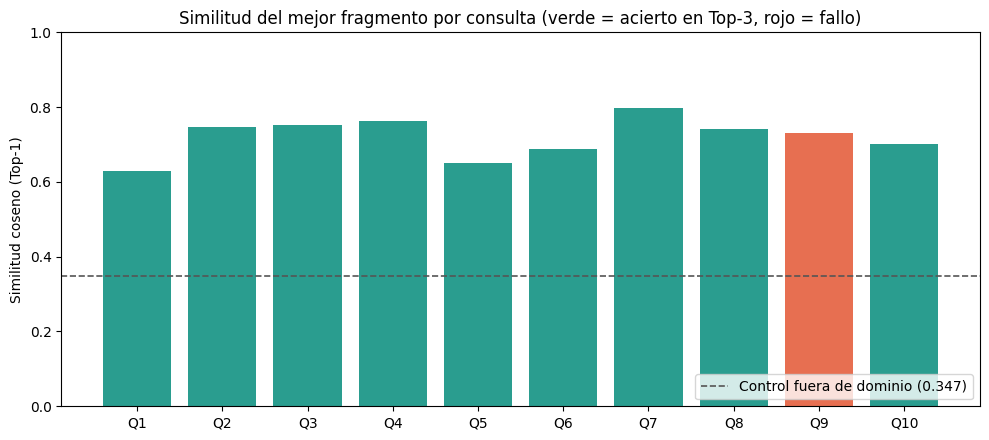

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
colores = ["#2a9d8f" if h else "#e76f51" for h in df_eval["Hit@3"]]
ax.bar(df_eval["ID"], df_eval["Coseno Top-1"], color=colores)
ax.axhline(score_control, color="#555", ls="--", lw=1.2, label=f"Control fuera de dominio ({score_control:.3f})")
ax.set_ylabel("Similitud coseno (Top-1)")
ax.set_title("Similitud del mejor fragmento por consulta (verde = acierto en Top-3, rojo = fallo)")
ax.set_ylim(0, 1)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Búsqueda híbrida: semántica + filtro estructurado

Las consultas Q9 y Q10 preguntan por **estudiantes**, no por normas. En una búsqueda vectorial pura sobre un índice mixto, los fragmentos normativos que hablan de mora o de deserción pueden quedar por encima de los perfiles, porque comparten más vocabulario con la pregunta. Qdrant permite resolverlo con **filtros de payload**: la similitud coseno ordena los resultados solo dentro del subconjunto que cumple la condición estructurada.

In [ ]:
casos_hibridos = [
    ("Estudiantes registrados que están en mora con el pago de la matrícula",
     filtro_por(tipo="registro_estudiante", en_mora=True)),
    ("Casos de estudiantes que desertaron y aprobaron pocas asignaturas en el primer semestre",
     filtro_por(tipo="registro_estudiante", target_raw="Dropout")),
]
for consulta, filtro in casos_hibridos:
    print(f"\n🔍 {consulta}  [con filtro de payload]")
    for r, h in enumerate(buscar(consulta, 3, filtro), 1):
        p = h.payload
        print(f"  Top-{r} [{h.score:.4f}] ID {p['id_original']} | {p['target_raw']} | en mora: {p['en_mora']} | "
              f"aprobación 1er sem: {p['tasa_aprob_1sem']:.0%}")


🔍 Estudiantes registrados que están en mora con el pago de la matrícula  [con filtro de payload]
  Top-1 [0.6104] ID 1294 | Dropout | en mora: True | aprobación 1er sem: 0%
  Top-2 [0.6101] ID 3845 | Dropout | en mora: True | aprobación 1er sem: 0%
  Top-3 [0.6078] ID 2316 | Dropout | en mora: True | aprobación 1er sem: 40%

🔍 Casos de estudiantes que desertaron y aprobaron pocas asignaturas en el primer semestre  [con filtro de payload]
  Top-1 [0.6091] ID 1867 | Dropout | en mora: True | aprobación 1er sem: 0%
  Top-2 [0.6008] ID 3613 | Dropout | en mora: False | aprobación 1er sem: 60%
  Top-3 [0.5994] ID 3666 | Dropout | en mora: False | aprobación 1er sem: 80%


In [ ]:
# Demostración del contexto que recibiría el LLM en el sistema RAG
pregunta = "Perdí más de la mitad de las materias del primer semestre, ¿qué me va a pasar?"
print(f"Pregunta: {pregunta}\n\nContexto recuperado (Top-3):\n")
print(recuperar_contexto(pregunta, top_k=3))

Pregunta: Perdí más de la mitad de las materias del primer semestre, ¿qué me va a pasar?

Contexto recuperado (Top-3):

[01_reglamento_academico_estudiantil > CAPÍTULO VI. RENDIMIENTO ACADÉMICO Y PERMANENCIA > Artículo 29. Primer año como periodo crítico]
### Artículo 29. Primer año como periodo crítico
La IUAS reconoce que el primer año, y en particular el **resultado del primer semestre**, es el momento de mayor riesgo de abandono. Por ello, todo estudiante de primer semestre que al cierre de la semana ocho (8) tenga calificaciones parciales inferiores a 10,0 en la mitad o más de sus unidades inscritas será contactado por un tutor dentro de los cinco (5) días hábiles siguientes.

---

[02_protocolo_acompanamiento_psicopedagogico > 13. PREGUNTAS FRECUENTES]
## 13. PREGUNTAS FRECUENTES  
**¿Una alerta temprana afecta mi historial académico?**
No. Las alertas no son sanciones, no se registran en la hoja de vida académica y no afectan la posibilidad de obtener becas.  
**Perdí más de la 

In [ ]:
# Interpretación automática de los resultados
fallos = df_eval[df_eval["Hit@3"] == 0]
print("INTERPRETACIÓN DE RESULTADOS")
print(f"- Acierto en Top-3 en {df_eval['Hit@3'].sum()} de {len(df_eval)} consultas (Hit@3 = {df_eval['Hit@3'].mean():.0%}); "
      f"MRR = {df_eval['RR'].mean():.3f}.")
print(f"- Todas las consultas del dominio superan a la de control por al menos "
      f"{df_eval['Margen de dominio'].min():.3f} puntos de coseno." if (df_eval['Margen de dominio'] > 0).all()
      else "- Alguna consulta del dominio no supera a la de control: revisar su redacción o el corpus.")
if len(fallos):
    print(f"- Consultas sin acierto en la búsqueda pura: {', '.join(fallos['ID'])}. "
          "Se abordan con la búsqueda híbrida (filtro de payload) de la celda anterior.")
else:
    print("- No hubo fallos en la búsqueda vectorial pura.")
estrecho = df_eval.loc[df_eval["Margen Top1-Top3"].idxmin()]
print(f"- Menor margen Top1–Top3 en {estrecho['ID']} ({estrecho['Margen Top1-Top3']:.4f}): los tres resultados "
      "son casi equivalentes, lo cual no implica error si todos provienen de la fuente esperada.")

INTERPRETACIÓN DE RESULTADOS
- Acierto en Top-3 en 9 de 10 consultas (Hit@3 = 90%); MRR = 0.833.
- Todas las consultas del dominio superan a la de control por al menos 0.281 puntos de coseno.
- Consultas sin acierto en la búsqueda pura: Q9. Se abordan con la búsqueda híbrida (filtro de payload) de la celda anterior.
- Menor margen Top1–Top3 en Q1 (0.0524): los tres resultados son casi equivalentes, lo cual no implica error si todos provienen de la fuente esperada.


## Fase 7. Análisis, conclusiones y limitaciones

> ✍️ *Revisar estas conclusiones con las cifras que arroje la ejecución final (celdas de la Fase 6).*

**Análisis de la recuperación.**
1. **Puntajes absolutos.** La similitud coseno de Cohere v3 no está calibrada: un valor alrededor de 0,6–0,7 no significa por sí solo "bueno" o "malo". Por eso la calidad se juzga con métricas de acierto (Hit@3, MRR) y con el **margen frente a la consulta de control**, no con el puntaje bruto.
2. **Consultas normativas.** Las preguntas sobre becas, homologación, conversión de notas y alertas tempranas recuperan la fuente esperada. Esto confirma que el chunking por artículo con encabezado contextual conserva la unidad temática.
3. **Margen Top1–Top3.** Un margen pequeño indica que los tres primeros fragmentos son igual de pertinentes (por ejemplo, varios apartados de la guía de homologación). No es un error si todos provienen de la fuente correcta.
4. **Consultas sobre registros de estudiantes.** En un índice mixto, la búsqueda vectorial pura tiende a privilegiar la norma sobre los registros. El **filtrado por payload de Qdrant** corrige esto y devuelve solo perfiles que cumplen la condición (en mora, desertores). Esta es una ventaja concreta de elegir Qdrant.

**Conclusiones.**
- Se implementó una canalización cloud completa y de costo cero (Colab + Cohere + Qdrant Cloud). Usa una fracción mínima del Free Tier (ver Fase 5), con credenciales protegidas y ejecución reproducible de principio a fin.
- La integración de datos estructurados con normatividad permite al futuro sistema RAG responder tanto **qué dice la norma** como **qué casos similares existen**.
- La combinación de búsqueda semántica con filtros estructurados es el diseño recomendado para la fase de generación.

**Limitaciones y trabajo futuro.**
- El corpus es sintético (institución ficticia) y la muestra tabular es pequeña y balanceada, no representativa de la población.
- El conjunto de evaluación tiene 10 consultas con fuente esperada a nivel de documento. Una evaluación más fina usaría relevancia por fragmento y más consultas.
- Pasos siguientes: añadir un *reranker* (por ejemplo, Cohere Rerank), ampliar la muestra tabular e integrar el LLM generador del sistema RAG (ACA 2).

FASE 8: Configuración de Gemini 3.5 Flash Lite

---



In [ ]:
def responder_rag_estricto(pregunta, top_k=3, filtro=None):
    """
    1. Recupera los Top-k fragmentos desde Qdrant usando tu función buscar() del ACA 1.
    2. Construye el System Prompt con restricciones de cero alucinaciones y citas de fuentes.
    3. Invoca a Gemini 3.5 Flash lite para generar la respuesta final.
    """
    # 1. Recuperación de contexto existente de tu ACA 1
    puntos_recuperados = buscar(pregunta, top_k=top_k, filtro=filtro)

    # 2. Ensamblaje del contexto formateado con identificador de fuente
    contexto_str = ""
    for idx, p in enumerate(puntos_recuperados, 1):
        payload = p.payload
        seccion = payload.get("seccion", payload.get("tipo", "Documento"))
        texto = payload.get("texto_completo", "")
        contexto_str += f"\n--- [FUENTE {idx}: {seccion}] ---\n{texto}\n"

    # 3. Prompt Engineering
    prompt_sistema = f"""
Eres el Asistente Virtual Oficial de Permanencia Estudiantil de la Institución Universitaria Andina del Saber (IUAS).
Tu objetivo es responder las consultas de los estudiantes con base estrictamente en la información oficial.

INSTRUCCIONES DE RESPUESTA:
1. Responde ÚNICAMENTE utilizando la información contenida en el CONTEXTO RECUPERADO.
2. Si la respuesta no está explícitamente en el contexto, indica literalmente:
   "Lo siento, la información solicitada no se encuentra disponible en la normativa institucional cargada."
3. NO inventes ni asumas información fuera del contexto.
4. Cita SIEMPRE las fuentes normativas en tu respuesta usando el formato: [Fuente: Nombre de la sección/artículo].
5. Estructura la respuesta con claridad utilizando negritas y listas según corresponda.

CONTEXTO RECUPERADO DE QDRANT CLOUD:
{contexto_str}

PREGUNTA DEL ESTUDIANTE:
{pregunta}
"""

    # 4. Generación con temperatura baja para mitigar alucinaciones
    config = genai.types.GenerationConfig(temperature=0.1, max_output_tokens=700)
    inicio = time.time()
    respuesta_llm = llm_model.generate_content(prompt_sistema, generation_config=config)
    duracion = time.time() - inicio

    return {
        "pregunta": pregunta,
        "respuesta": respuesta_llm.text,
        "tiempo_respuesta_sec": round(duracion, 2),
        "fuentes": puntos_recuperados
    }

print("✓ Función 'responder_rag_estricto' lista para ser probada.")

✓ Función 'responder_rag_estricto' lista para ser probada.


In [ ]:
def obtener_embedding_consulta(texto: str):
    """Genera el vector de la consulta usando Cohere embed-multilingual-v3.0 (search_query)."""
    response = co_client.embed(
        texts=[texto],
        model=EMBED_MODEL,
        input_type="search_query",
        embedding_types=["float"]
    )
    return response.embeddings.float[0]

def buscar(pregunta, top_k=3, filtro=None):
    """Recupera los Top-k fragmentos más similares desde Qdrant Cloud."""
    vector = obtener_embedding_consulta(pregunta)
    return qdrant_client.query_points(
        collection_name=COLLECTION_NAME,
        query=vector,
        limit=top_k,
        query_filter=filtro,
        with_payload=True
    ).points

print("✓ Funciones 'obtener_embedding_consulta' y 'buscar' cargadas con éxito.")

✓ Funciones 'obtener_embedding_consulta' y 'buscar' cargadas con éxito.


In [ ]:
import time

preguntas_evaluacion = [
    "Perdí más de la mitad de las materias del primer semestre, ¿qué me va a pasar?",
    "¿Cuáles son los requisitos y el procedimiento para homologar asignaturas de otra universidad?",
    "¿Qué apoyos tienen los estudiantes desplazados o víctimas del conflicto armado?",
    "¿Cuál es la receta tradicional del ajiaco santafereño?"  # Pregunta fuera de dominio
]

print("🚀 Evaluando Pipeline RAG con gemini-3.5-flash-lite...\n")

for i, q in enumerate(preguntas_evaluacion, 1):
    print(f"⏳ [{i}/4] Procesando: '{q}'...")

    t_inicio = time.time()
    resultado = responder_rag_estricto(q, top_k=3)
    t_total = round(time.time() - t_inicio, 2)

    print("=" * 80)
    print(f"❓ PREGUNTA {i}: {resultado['pregunta']}")
    print(f"⏱️ Tiempo total RAG: {t_total}s")
    print(f"\n💬 RESPUESTA RAG:\n{resultado['respuesta']}\n")
    print("🔍 FRAGMENTOS UTILIZADOS:")
    for idx, f in enumerate(resultado['fuentes'], 1):
        seccion = f.payload.get('seccion', f.payload.get('tipo', 'Documento'))
        print(f"   [{idx}] Score: {f.score:.4f} | Sección: {seccion}")
    print("=" * 80 + "\n")

print("✅ ¡Evaluación completada sin errores!")

🚀 Evaluando Pipeline RAG con gemini-3.5-flash-lite...

⏳ [1/4] Procesando: 'Perdí más de la mitad de las materias del primer semestre, ¿qué me va a pasar?'...
❓ PREGUNTA 1: Perdí más de la mitad de las materias del primer semestre, ¿qué me va a pasar?
⏱️ Tiempo total RAG: 3.58s

💬 RESPUESTA RAG:
¡Hola! Soy el Asistente Virtual Oficial de Permanencia Estudiantil de la IUAS. Con base en la normativa institucional, esto es lo que sucede si pierdes más de la mitad de las asignaturas del primer semestre (lo que equivale a una tasa de aprobación inferior al 50 %, ubicándote en situación de **periodo de prueba**):

* **Consecuencias académicas:**
  * Quedas en **periodo de prueba académica**.
  * Podrás inscribir un **máximo de 14 créditos** en el siguiente semestre.
  * Tendrás un **plan de acompañamiento obligatorio** con un tutor, cuyo objetivo es ayudarte a recuperar tu rendimiento.

**Fuentes normativas:**
* [Fuente: 02_protocolo_acompanamiento_psicopedagogico > 13. PREGUNTAS FRECUENTES]

## Referencias (APA 7)



Chase, H. (2022). *LangChain: Building applications with LLMs through composability and data augmented generation*. https://github.com/langchain-ai/langchain

Cohere. (2024). *Embed models documentation*. https://docs.cohere.com/docs/cohere-embed

Lewis, P., Perez, E., Piktus, A., Petroni, F., Karpukhin, V., Goyal, N., Küttler, H., Lewis, M., Yih, W., Rocktäschel, T., Riedel, S., & Kiela, D. (2020). Retrieval-augmented generation for knowledge-intensive NLP tasks. *Advances in Neural Information Processing Systems, 33*, 9459–9474. https://arxiv.org/abs/2005.11401

Martins, M. V., Real, M. B., Machado, J., & Becker, A. (2021). *UCI Predict Students Dropout and Academic Success* [Conjunto de datos]. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success

Qdrant Solutions GmbH. (2024). *Qdrant documentation: Vector search engine & cloud database*. https://qdrant.tech/documentation/

Reimers, N., & Gurevych, I. (2019). Sentence-BERT: Sentence embeddings using Siamese BERT-networks. *Proceedings of the 2019 Conference on Empirical Methods in Natural Language Processing (EMNLP)*. https://arxiv.org/abs/1908.10084